# Part 0: Set up the environment

In [1]:
pip install torch


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


AI Declaration:
- Codex was helped the process of idea refining after initial idea drafting, strcutured planning, code hinting and code editing, the README file and report also require some assistance on codex in reviewing the structure and language polishing
- Claude was applied as a judger to judge the finished initial version, taking necessary comments and edit the files based on that 

In [2]:
import sys
import platform
import torch

print("Python:", sys.version.split()[0])
print("Python executable:", sys.executable)
print("Machine:", platform.machine())
print("PyTorch:", torch.__version__)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Training device:", device)

Python: 3.13.5
Python executable: /opt/anaconda3/bin/python
Machine: arm64
PyTorch: 2.9.1
Training device: mps


In [3]:
torch.manual_seed(42)
x = torch.tensor([1.0, 2.0], device=device, requires_grad=True)
loss = x.square().sum()
loss.backward()

assert torch.allclose(x.grad.cpu(), torch.tensor([2.0, 4.0]))
print("PyTorch calculation and gradient check passed.")

PyTorch calculation and gradient check passed.


# Part 1: Language Model Training and Comparison

## 1.1 Dataset selection and dataset splitting
This project chose news text as the English corpus for training, testing and evaluation. We will train language models on news text in Parts I–II, then use their representations to classify news topics in Part III.
Data Source: https://huggingface.co/datasets/fancyzhx/ag_news

Dataset spltting:
- 20,000 training examples: 5,000 per topic.
- 2,000 validation examples: 500 per topic, drawn from the official training split.
- 7,600 test examples: the complete official test split.
All three parts will use these same saved splits. Labels are used for balanced sampling now and classifier training in Part III; the language models will only receive text.

### 1.1.1 Install the dataset loader

In [4]:
%pip install datasets


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


### 1.1.2 Import and Clean Dataset
The original dataset has already splt training and test sets. A separate validation split was comoing from from the original training data.

In [5]:
from pathlib import Path
from collections import Counter
import hashlib
import html
import json
import random
import sys
import datasets
from datasets import DatasetDict, load_dataset

PROJECT_DIR = Path("/Users/caleb/Desktop/DSA4213/Assignment_1")
DATA_DIR = PROJECT_DIR / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

DATASET_ID = "fancyzhx/ag_news"
SEED = 2026
TRAIN_PER_CLASS = 5_000
VALIDATION_PER_CLASS = 500

raw = load_dataset(DATASET_ID, cache_dir=str(DATA_DIR / "hf_cache"))
label_names = raw["train"].features["label"].names
print(raw)
print("Topics:", label_names)


DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})
Topics: ['World', 'Sports', 'Business', 'Sci/Tech']


### 1.1.3 Create separate, balanced training and validation sets
News datasets can contain repeated text. Before splitting, we remove empty examples, repeated texts, and texts that match test texts. We compare text after ignoring case, HTML escapes, and whitespace differences; the stored text itself remains unchanged.

This check catches exact matches under that normalization, not every near-duplicate or related story. We will note that limitation in the report.
We then sample each topic using a fixed random seed. The official test split stays intact.

In [6]:
def text_key(text):
    return " ".join(html.unescape(text).lower().split())

# only to check overlap, not to train any model.
test_keys = {text_key(text) for text in raw["test"]["text"]}
seen = set()
by_label = {label: [] for label in range(len(label_names))}
removed = Counter()

for index, example in enumerate(raw["train"]):
    key = text_key(example["text"])
    if not key:
        removed["empty"] += 1
    elif key in test_keys:
        removed["matches_test"] += 1
    elif key in seen:
        removed["duplicate_training_text"] += 1
    else:
        seen.add(key)
        by_label[example["label"]].append(index)

rng = random.Random(SEED)
train_indices, validation_indices = [], []
for label, candidates in by_label.items():
    required = TRAIN_PER_CLASS + VALIDATION_PER_CLASS
    if len(candidates) < required:
        raise ValueError(f"Not enough distinct training texts for {label_names[label]}")
    selected = rng.sample(candidates, required)
    train_indices.extend(selected[:TRAIN_PER_CLASS])
    validation_indices.extend(selected[TRAIN_PER_CLASS:])

rng.shuffle(train_indices)
rng.shuffle(validation_indices)
corpus = DatasetDict({
    "train": raw["train"].select(train_indices),
    "validation": raw["train"].select(validation_indices),
    "test": raw["test"],
})

train_keys = {text_key(text) for text in corpus["train"]["text"]}
validation_keys = {text_key(text) for text in corpus["validation"]["text"]}
assert train_keys.isdisjoint(validation_keys)
assert train_keys.isdisjoint(test_keys)
assert validation_keys.isdisjoint(test_keys)
assert len(train_keys) == len(corpus["train"])
assert len(validation_keys) == len(corpus["validation"])
for label in range(len(label_names)):
    assert Counter(corpus["train"]["label"])[label] == TRAIN_PER_CLASS
    assert Counter(corpus["validation"]["label"])[label] == VALIDATION_PER_CLASS

print("Removed from the training candidate pool:", dict(removed))
print("Split separation and class-balance checks passed.")


Removed from the training candidate pool: {'duplicate_training_text': 151, 'matches_test': 10}
Split separation and class-balance checks passed.


### 1.1.4 Inspect the size and training examples
The approximate word counts were accessed using whitespace splitting, and we will define the actual tokenizer next. Read one training example from each topic. We do not inspect test examples to make preprocessing decisions

In [7]:
for name, split in corpus.items():
    words = sum(len(text.split()) for text in split["text"])
    counts = Counter(split["label"])
    print(f"{name:10s} | examples: {len(split):,} | approximate words: {words:,}")
    print("  Topics:", {label_names[label]: counts[label] for label in range(len(label_names))})

print("\nOne training example per topic:")
shown = set()
for example in corpus["train"]:
    label = example["label"]
    if label not in shown:
        print(f"\n{label_names[label]}:\n{example['text']}")
        shown.add(label)
    if len(shown) == len(label_names):
        break



train      | examples: 20,000 | approximate words: 757,017
  Topics: {'World': 5000, 'Sports': 5000, 'Business': 5000, 'Sci/Tech': 5000}
validation | examples: 2,000 | approximate words: 74,841
  Topics: {'World': 500, 'Sports': 500, 'Business': 500, 'Sci/Tech': 500}
test       | examples: 7,600 | approximate words: 286,690
  Topics: {'World': 1900, 'Sports': 1900, 'Business': 1900, 'Sci/Tech': 1900}

One training example per topic:

Sports:
Rape Charge Against NBA Star Kobe Bryant Dropped District Attorney Mark Hurlbert said he filed the motion to dismiss the criminal case Wednesday because Bryant #39;s 20-year-old accuser was no longer willing to testify.

Sci/Tech:
Grand Theft Auto San Andreas leaked First it was Halo 2, now GTA. The new iteration of the popular Grand Theft Auto franchise was supposed to hit retails shelves by the end of October however pirated 

Business:
Four key steps in Murdoch #39;s US march RUPERT Murdoch has to win four key votes to shift The News Corporation

### 1.1.5 Save the experiment data and sampling splits
The saved splits are re-used for every comparison. Only training text will be used to build the vocabulary and train the word embeddings.

In [8]:
saved_path = DATA_DIR / "ag_news_experiment"
corpus.save_to_disk(str(saved_path))
manifest = {
    "dataset_id": DATASET_ID,
    "source_url": "https://huggingface.co/datasets/fancyzhx/ag_news",
    "seed": SEED,
    "train_per_class": TRAIN_PER_CLASS,
    "validation_per_class": VALIDATION_PER_CLASS,
    "label_names": label_names,
    "datasets_version": datasets.__version__,
    "python_version": sys.version,
    "raw_fingerprints": {name: split._fingerprint for name, split in raw.items()},
    "split_rows": {name: len(split) for name, split in corpus.items()},
    "train_source_indices": train_indices,
    "validation_source_indices": validation_indices,
    "test_selection": "Complete official test split; original order retained.",
    "training_candidates_removed": dict(removed),
    "overlap_check": "Lowercase, HTML-unescaped text with normalized whitespace; near-duplicates not checked.",
    "preprocessing": "Stored text unchanged; cleaning and tokenization are the next step.",
}
manifest_path = DATA_DIR / "ag_news_manifest.json"
manifest_path.write_text(json.dumps(manifest, indent=2) + "\n", encoding="utf-8")
print("Saved dataset to:", saved_path)
print("Saved source and split information to:", manifest_path)


Saving the dataset (0/1 shards):   0%|          | 0/20000 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/2000 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/7600 [00:00<?, ? examples/s]

Saved dataset to: /Users/caleb/Desktop/DSA4213/Assignment_1/data/ag_news_experiment
Saved source and split information to: /Users/caleb/Desktop/DSA4213/Assignment_1/data/ag_news_manifest.json


## 1.2 Tokenization and a training-only vocabulary
We are performing two transformations in the following sections:
1. Split text into tokens: words and punctuation.
2. Assign each vocabulary token an integer ID.

We use the same tokenizer and vocabulary for all language models and embedding variants. This makes their next-token losses comparable and allows us to look up public word embeddings later.

### 1.2.1 Text-processing helper
We created dsa4213_text.py to store the functions that help with text processing

The module was implemented using Python's standard library, including regular expressions (re), HTML handling (html), Unicode normalization (unicodedata), and token counting (collections.Counter). It provides:

| Function | Purpose |
| :--- | :--- |
| `clean_text()` | Normalize formatting and typography, lowercase text, and normalize whitespace. |
| `tokenize()` | Separate words and punctuation using a regular expression, preserving contractions such as can't. |
| `build_vocabulary()` | Count tokens from training text only and assign IDs according to the frequency threshold and vocabulary-size limit. Tokens are ordered by frequency, with alphabetical ordering to resolve ties reproducibly. |
| `encode_text()` | Convert each news item into IDs, replace unknown tokens with `<unk>`, and add `<bos>` and `<eos>` boundary markers. |
| `decode_ids()` | Convert IDs back into tokens for inspection. |

### 1.2.2 Load the saved experiment splits

In [9]:
from pathlib import Path
from collections import Counter
import hashlib
import json
import sys
from datasets import load_from_disk

PROJECT_DIR = Path("/Users/caleb/Desktop/DSA4213/Assignment_1")
DATA_DIR = PROJECT_DIR / "data"
source_path = DATA_DIR / "ag_news_experiment"
if not source_path.exists():
    raise FileNotFoundError(
        "Saved experiment splits are missing. Run all cells of 01_dataset.ipynb, "
        "including its final save cell, and then return here."
    )

if str(PROJECT_DIR) in sys.path:
    sys.path.remove(str(PROJECT_DIR))
sys.path.insert(0, str(PROJECT_DIR))
from dsa4213_text import clean_text, tokenize, build_vocabulary, encode_text, decode_ids

corpus = load_from_disk(str(source_path))
print({name: len(split) for name, split in corpus.items()})


{'train': 20000, 'validation': 2000, 'test': 7600}


### 1.2.3 Tokenize the sentence
We lowercase text, normalize typography and HTML formatting, and split words and punctuation. Contractions such as can't remain one token. Numeric strings are retained; rare ones may later map to <unk>.

In [10]:
example_text = "The team’s fans can't believe it won!"
print("Original:", example_text)
print("Cleaned:", clean_text(example_text))
print("Tokens:", tokenize(example_text))

print("\nAn actual training example:")
news_text = corpus["train"][0]["text"]
print(news_text)
print("Tokens:", tokenize(news_text))


Original: The team’s fans can't believe it won!
Cleaned: the team's fans can't believe it won!
Tokens: ['the', "team's", 'fans', "can't", 'believe', 'it', 'won', '!']

An actual training example:
Rape Charge Against NBA Star Kobe Bryant Dropped District Attorney Mark Hurlbert said he filed the motion to dismiss the criminal case Wednesday because Bryant #39;s 20-year-old accuser was no longer willing to testify.
Tokens: ['rape', 'charge', 'against', 'nba', 'star', 'kobe', 'bryant', 'dropped', 'district', 'attorney', 'mark', 'hurlbert', 'said', 'he', 'filed', 'the', 'motion', 'to', 'dismiss', 'the', 'criminal', 'case', 'wednesday', 'because', 'bryant', "'", 's', '20', '-', 'year', '-', 'old', 'accuser', 'was', 'no', 'longer', 'willing', 'to', 'testify', '.']


### 1.2.4 Build the training texts from training set
We keep at most 10,000 entries, including four special tokens. Ordinary tokens must appear at least twice in the training text. The rest map to <unk>.
- `<pad>`: fills shorter sequences when we batch them; excluded from loss.
- `<unk>`: represents words outside the training vocabulary.
- `<bos>`: marks the beginning of one news item.
- `<eos>`: marks its end.

In [11]:
MAX_VOCAB_SIZE = 10_000
MIN_FREQUENCY = 2

token_to_id, id_to_token, training_counts = build_vocabulary(
    corpus["train"]["text"],
    max_size=MAX_VOCAB_SIZE,
    min_frequency=MIN_FREQUENCY,
)
print("Training tokens before boundary markers:", f"{sum(training_counts.values()):,}")
print("Distinct training tokens:", f"{len(training_counts):,}")
print("Vocabulary size including special tokens:", f"{len(id_to_token):,}")
print("Special token IDs:", {token: token_to_id[token] for token in id_to_token[:4]})
print("Most frequent training tokens:", training_counts.most_common(15))


Training tokens before boundary markers: 892,040
Distinct training tokens: 34,018
Vocabulary size including special tokens: 10,000
Special token IDs: {'<pad>': 0, '<unk>': 1, '<bos>': 2, '<eos>': 3}
Most frequent training tokens: [('.', 35909), ('the', 34313), (',', 27576), ('-', 23456), ('to', 20136), ('a', 18168), ('of', 16458), ('in', 16071), ('and', 11459), ('on', 9633), ("'", 8554), ('for', 8415), ('(', 6938), (')', 6876), ('s', 6652)]


### 1.2.4. Encode each split using that same fixed vocabulary
We preserve one sequence per news item. Models should not learn transitions from the end of one unrelated story into the start of the next. The topic label is retained for Part III, but must not be fed to the language models. No padding or truncation is applied here. 

In [12]:
def encode_example(example):
    return {"input_ids": encode_text(example["text"], token_to_id)}

encoded = corpus.map(encode_example, desc="Tokenizing news text")
unk_id = token_to_id["<unk>"]

# Show training/validation diagnostics. We do not use test diagnostics to tune preprocessing.
for name in ("train", "validation"):
    sequences = encoded[name]["input_ids"]
    token_count = sum(len(ids) - 2 for ids in sequences)
    unknown_count = sum(ids.count(unk_id) for ids in sequences)
    lengths = sorted(len(ids) for ids in sequences)
    p95_index = max(0, (95 * len(lengths) + 99) // 100 - 1)
    print(
        f"{name:10s} | tokens: {token_count:,} | "
        f"unknown: {100 * unknown_count / max(token_count, 1):.2f}% | "
        f"mean length incl. boundaries: {sum(lengths) / len(lengths):.1f} | "
        f"95th percentile length: {lengths[p95_index]}"
    )

first_ids = encoded["train"][0]["input_ids"]
print("\nFirst 25 token IDs:", first_ids[:25])
print("Their tokens:", decode_ids(first_ids[:25], id_to_token))


train      | tokens: 892,040 | unknown: 5.28% | mean length incl. boundaries: 46.6 | 95th percentile length: 66
validation | tokens: 87,966 | unknown: 6.24% | mean length incl. boundaries: 46.0 | 95th percentile length: 65

First 25 token IDs: [2, 3010, 1007, 71, 753, 495, 2527, 1793, 1396, 2033, 1472, 554, 1, 28, 55, 958, 5, 1757, 8, 8908, 5, 1926, 392, 64, 354]
Their tokens: ['<bos>', 'rape', 'charge', 'against', 'nba', 'star', 'kobe', 'bryant', 'dropped', 'district', 'attorney', 'mark', '<unk>', 'said', 'he', 'filed', 'the', 'motion', 'to', 'dismiss', 'the', 'criminal', 'case', 'wednesday', 'because']


### 1.2.5 Next-token inputs and targets

For a sequence [<bos>, the, team, won, <eos>], inputs are [<bos>, the, team, won] and targets are [the, team, won, <eos>].

Each input predicts the token immediately after it. This alignment alone does not enforce causality: the RNN/LSTM must be unidirectional, and the Transformer needs a causal attention mask.

In [13]:
toy_ids = encode_text("The team won.", token_to_id)
inputs = toy_ids[:-1]
targets = toy_ids[1:]
print("Example: The team won.")
print("Inputs: ", decode_ids(inputs, id_to_token))
print("Targets:", decode_ids(targets, id_to_token))
assert len(inputs) == len(targets)


Example: The team won.
Inputs:  ['<bos>', 'the', 'team', 'won', '.']
Targets: ['the', 'team', 'won', '.', '<eos>']


### 1.2.6. Check and save the preprocessing artifacts
Checks confirm that IDs are valid, every item has boundaries, and vocabulary entries came from training text. Later notebooks will load these saved sequences and this exact vocabulary.

In [14]:
assert id_to_token[:4] == ["<pad>", "<unk>", "<bos>", "<eos>"]
assert len(token_to_id) == len(id_to_token)
assert len(id_to_token) <= MAX_VOCAB_SIZE
assert all(training_counts[token] >= MIN_FREQUENCY for token in id_to_token[4:])

for name, split in encoded.items():
    assert len(split) == len(corpus[name])
    for ids in split["input_ids"]:
        assert ids[0] == token_to_id["<bos>"]
        assert ids[-1] == token_to_id["<eos>"]
        assert all(0 <= value < len(id_to_token) for value in ids)
        assert token_to_id["<pad>"] not in ids

output_path = DATA_DIR / "ag_news_tokenized"
encoded.save_to_disk(str(output_path))
vocab_payload = {
    "token_to_id": token_to_id,
    "id_to_token": id_to_token,
    "max_vocab_size": MAX_VOCAB_SIZE,
    "min_frequency": MIN_FREQUENCY,
    "fit_split": "train",
}
(DATA_DIR / "vocabulary.json").write_text(
    json.dumps(vocab_payload, ensure_ascii=False, indent=2) + "\n", encoding="utf-8"
)
manifest = {
    "source_fingerprints": {name: split._fingerprint for name, split in corpus.items()},
    "vocabulary_size": len(id_to_token),
    "max_vocab_size": MAX_VOCAB_SIZE,
    "min_frequency": MIN_FREQUENCY,
    "vocabulary_fit_split": "train",
    "boundary_policy": "Each news item separately; prepend <bos> and append <eos>.",
    "padding": "None at this step.",
    "truncation": "None at this step.",
    "tokenizer_source_sha256": hashlib.sha256((PROJECT_DIR / "dsa4213_text.py").read_bytes()).hexdigest(),
}
(DATA_DIR / "preprocessing_manifest.json").write_text(
    json.dumps(manifest, indent=2) + "\n", encoding="utf-8"
)
print("Vocabulary and sequence checks passed.")
print("Saved tokenized data to:", output_path)


Saving the dataset (0/1 shards):   0%|          | 0/20000 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/2000 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/7600 [00:00<?, ? examples/s]

Vocabulary and sequence checks passed.
Saved tokenized data to: /Users/caleb/Desktop/DSA4213/Assignment_1/data/ag_news_tokenized


## 1.3 n-gram language model
An n-gram model counts tokens and their preceding contexts:
- Unigram: how often a token appears overall.
- Bigram: how often a token follows one preceding token.
- Trigram: how often a token follows two preceding tokens.

### 1.3.1 Load existing data and define the prediction vocabulary
`<pad>` and `<bos>` are input/control symbols, so the model predicts vocabulary entries other than those two. It can predict `<unk>` and `<eos>`.

Later neural models must use this same target policy, tokenization, vocabulary, and evaluation text. Their prediction distribution should also exclude `<pad>` and `<bos>`.

In [15]:
import math
import time
import pickle

# Reuse the vocabulary and encoded splits from Section 1.2.
PAD_ID = token_to_id["<pad>"]
UNK_ID = token_to_id["<unk>"]
BOS_ID = token_to_id["<bos>"]
EOS_ID = token_to_id["<eos>"]

# Beginning-of-sequence and padding are not prediction targets.
PREDICTABLE_IDS = [
    token_id
    for token_id in range(len(id_to_token))
    if token_id not in (PAD_ID, BOS_ID)
]

train_sequences = encoded["train"]["input_ids"]
validation_sequences = encoded["validation"]["input_ids"]
test_sequences = encoded["test"]["input_ids"]

print("Vocabulary size:", len(id_to_token))
print("Predictable tokens:", len(PREDICTABLE_IDS))

Vocabulary size: 10000
Predictable tokens: 9998


### 1.3.2 Implement the model
For a candidate next token w, use: P(w | history) = λ₁ × P_unigram(w) + λ₂ × P_bigram(w | previous) + λ₃ × P_trigram(w | last two)
The weights sum to one. 

The unigram estimate uses add-alpha smoothing:
P_unigram(w) = (count(w) + alpha) / (total target tokens + alpha × predictable vocabulary size)

Bigram and trigram estimates use observed relative frequencies. An unseen bigram context falls back to the smoothed unigram distribution; an unseen trigram context falls back to the bigram distribution. With positive alpha and a positive unigram weight, every permitted next token has positive probability.

At the beginning of a news item, we use two`<bos>` context markers. These markers are not prediction targets. `<eos>` is a target. We do not count transitions between unrelated news items.

In [16]:
class InterpolatedNGram:
    def __init__(self, predictable_ids, bos_id, eos_id, pad_id):
        self.predictable_ids = tuple(predictable_ids)
        self.allowed = set(predictable_ids)
        self.bos_id, self.eos_id, self.pad_id = bos_id, eos_id, pad_id
        self.unigrams = Counter()
        self.bigrams = Counter()
        self.trigrams = Counter()
        self.bigram_totals = Counter()
        self.trigram_totals = Counter()
        self.total_targets = 0

    def fit(self, sequences):
        # Reset counts so rerunning this cell does not double-count training data.
        self.unigrams.clear()
        self.bigrams.clear()
        self.trigrams.clear()
        self.bigram_totals.clear()
        self.trigram_totals.clear()
        self.total_targets = 0
        for sequence in sequences:
            if len(sequence) < 2 or sequence[0] != self.bos_id or sequence[-1] != self.eos_id:
                raise ValueError("Each sequence must have beginning/end markers")
            older = previous = self.bos_id
            for target in sequence[1:]:
                if target not in self.allowed:
                    raise ValueError("A target is padding, <bos>, or outside the vocabulary")
                self.unigrams[target] += 1
                self.bigrams[(previous, target)] += 1
                self.trigrams[(older, previous, target)] += 1
                self.bigram_totals[previous] += 1
                self.trigram_totals[(older, previous)] += 1
                self.total_targets += 1
                older, previous = previous, target
        if self.total_targets == 0:
            raise ValueError("Training data has no prediction targets")
        return self

    @staticmethod
    def check_settings(weights, alpha):
        if len(weights) != 3 or any(weight < 0 for weight in weights):
            raise ValueError("Use three nonnegative interpolation weights")
        if not math.isclose(sum(weights), 1.0) or weights[0] <= 0 or alpha <= 0:
            raise ValueError("Weights must sum to 1, with positive unigram weight and alpha")

    def probability(self, target, context, weights, alpha):
        # Settings are validated once by evaluate/distribution, outside this hot loop.
        if target not in self.allowed:
            return 0.0
        older, previous = context
        unigram = (self.unigrams[target] + alpha) / (
            self.total_targets + alpha * len(self.predictable_ids)
        )
        bigram_total = self.bigram_totals[previous]
        bigram = self.bigrams[(previous, target)] / bigram_total if bigram_total else unigram
        trigram_total = self.trigram_totals[(older, previous)]
        trigram = self.trigrams[(older, previous, target)] / trigram_total if trigram_total else bigram
        return weights[0] * unigram + weights[1] * bigram + weights[2] * trigram

    def distribution(self, history, weights, alpha):
        self.check_settings(weights, alpha)
        context = tuple(([self.bos_id, self.bos_id] + list(history))[-2:])
        return [self.probability(target, context, weights, alpha) for target in self.predictable_ids]

    def evaluate(self, sequences, weights, alpha):
        self.check_settings(weights, alpha)
        negative_log_likelihood, target_count = 0.0, 0
        for sequence in sequences:
            if len(sequence) < 2 or sequence[0] != self.bos_id or sequence[-1] != self.eos_id:
                raise ValueError("Evaluation sequences must have beginning/end markers")
            older = previous = self.bos_id
            for target in sequence[1:]:
                if target not in self.allowed:
                    raise ValueError("Evaluation must use unpadded sequences and allowed targets")
                probability = self.probability(target, (older, previous), weights, alpha)
                negative_log_likelihood -= math.log(probability)
                target_count += 1
                older, previous = previous, target
        if not target_count:
            raise ValueError("Evaluation has no prediction targets")
        cross_entropy = negative_log_likelihood / target_count
        return {
            "cross_entropy_nats": cross_entropy,
            "perplexity": math.exp(cross_entropy),
            "target_tokens": target_count,
        }

    def state(self):
        # Store plain data rather than pickling a notebook-local class definition.
        return {
            "predictable_ids": self.predictable_ids,
            "bos_id": self.bos_id, "eos_id": self.eos_id, "pad_id": self.pad_id,
            "unigrams": dict(self.unigrams), "bigrams": dict(self.bigrams),
            "trigrams": dict(self.trigrams), "bigram_totals": dict(self.bigram_totals),
            "trigram_totals": dict(self.trigram_totals), "total_targets": self.total_targets,
        }


### 1.3.3 Train by counting

In [17]:
import time
import pickle

model = InterpolatedNGram(PREDICTABLE_IDS, BOS_ID, EOS_ID, PAD_ID)
started = time.perf_counter()
model.fit(train_sequences)
training_seconds = time.perf_counter() - started
model_bytes = pickle.dumps(model.state(), protocol=pickle.HIGHEST_PROTOCOL)

print(f"Training time: {training_seconds:.3f} seconds")
print(f"Training prediction targets (including <eos>): {model.total_targets:,}")
print(f"Distinct unigram/bigram/trigram entries: {len(model.unigrams):,} / {len(model.bigrams):,} / {len(model.trigrams):,}")
print(f"Serialized count-table size: {len(model_bytes) / (1024 ** 2):.2f} MiB")


Training time: 1.212 seconds
Training prediction targets (including <eos>): 912,040
Distinct unigram/bigram/trigram entries: 9,998 / 279,581 / 601,924
Serialized count-table size: 11.62 MiB


### 1.3.4. Choose interpolation settings using validation data
This is a small search, not an exhaustive tuning exercise. alpha is fixed at 0.1. A few interpolation combinations were tried out and compared. The unigram and bigram candidates show whether extra context helps on this corpus. All candidates use the same stored training counts. 

Cross-entropy: average negative log probability assigned to the correct next token. Perplexity: exp(cross-entropy) when using natural logarithms. Lower is better. Average over prediction tokens, not over news items; include `<eos>` and exclude padding and `<bos>` targets.

In [18]:
import math

ALPHA = 0.1
CANDIDATES = [
    ("unigram", (1.0, 0.0, 0.0)),
    ("bigram", (0.1, 0.9, 0.0)),
    ("trigram_A", (0.1, 0.3, 0.6)),
    ("trigram_B", (0.2, 0.4, 0.4)),
    ("trigram_C", (0.3, 0.5, 0.2)),
]
validation_results = []
for name, weights in CANDIDATES:
    metrics = model.evaluate(validation_sequences, weights, ALPHA)
    row = {"name": name, "weights": list(weights), "alpha": ALPHA, **metrics}
    validation_results.append(row)
    print(f"{name:10s} | weights: {weights} | CE: {metrics['cross_entropy_nats']:.4f} | perplexity: {metrics['perplexity']:.2f}")

best = min(validation_results, key=lambda row: row["cross_entropy_nats"])
BEST_WEIGHTS = tuple(best["weights"])
print("\nSelected using validation only:", best["name"], BEST_WEIGHTS)

# Check normalization on observed and unseen contexts.
for history in ([BOS_ID], train_sequences[0][:3], [UNK_ID, UNK_ID]):
    probabilities = model.distribution(history, BEST_WEIGHTS, ALPHA)
    assert all(probability > 0 for probability in probabilities)
    assert math.isclose(sum(probabilities), 1.0, abs_tol=1e-9)
print("Probability checks passed.")


unigram    | weights: (1.0, 0.0, 0.0) | CE: 6.6781 | perplexity: 794.83
bigram     | weights: (0.1, 0.9, 0.0) | CE: 5.4591 | perplexity: 234.88
trigram_A  | weights: (0.1, 0.3, 0.6) | CE: 5.2075 | perplexity: 182.64
trigram_B  | weights: (0.2, 0.4, 0.4) | CE: 5.0906 | perplexity: 162.48
trigram_C  | weights: (0.3, 0.5, 0.2) | CE: 5.0960 | perplexity: 163.37

Selected using validation only: trigram_B (0.2, 0.4, 0.4)
Probability checks passed.


### 1.3.5 Train and measure prediction quality on the test set
Training is counting on the CPU. Loss is averaged over prediction tokens, including `<eos>` and excluding padding and `<bos>`. Perplexity is `exp(cross-entropy)` with natural logarithms. Keep this evaluation policy for all four models; do not tune on test scores.

Stored count-table size is reported below. It is not runtime RAM usage or a neural parameter count. Keep the vocabulary fixed when comparing scores.

In [19]:
# Evaluate the existing model; do not train another one.
test_metrics = model.evaluate(
    test_sequences,
    BEST_WEIGHTS,
    ALPHA,
)

ngram_result = {
    "model": "N-gram",
    "weights": list(BEST_WEIGHTS),
    "alpha": ALPHA,
    "validation_cross_entropy": best["cross_entropy_nats"],
    "validation_perplexity": best["perplexity"],
    "test_cross_entropy": test_metrics["cross_entropy_nats"],
    "test_perplexity": test_metrics["perplexity"],
    "training_seconds": training_seconds,
    "stored_model_size_mib": len(model_bytes) / (1024 ** 2),
}

print("Selected weights:", BEST_WEIGHTS)
print(f"Test cross-entropy: {ngram_result['test_cross_entropy']:.4f}")
print(f"Test perplexity: {ngram_result['test_perplexity']:.2f}")
print(f"Training time: {training_seconds:.3f} seconds")
print(f"Stored model size: {ngram_result['stored_model_size_mib']:.2f} MiB")

Selected weights: (0.2, 0.4, 0.4)
Test cross-entropy: 5.0912
Test perplexity: 162.59
Training time: 1.212 seconds
Stored model size: 11.62 MiB


### 1.3.6 Inference speed
We measure how long it takes to produce a full next-token probability distribution. Keep the same timing_contexts for the neural models later.

In [20]:
import statistics

# Collect 100 validation prefixes, each containing at most 64 tokens.
timing_contexts = []

for sequence in validation_sequences:
    for position in range(1, len(sequence)):
        context = sequence[max(0, position - 64):position]
        timing_contexts.append(context)

        if len(timing_contexts) == 100:
            break

    if len(timing_contexts) == 100:
        break

# Warm-up pass: exclude this from the timing.
for context in timing_contexts:
    model.distribution(context, BEST_WEIGHTS, ALPHA)

# Repeat the measurement three times.
timings = []

for _ in range(3):
    started = time.perf_counter()

    for context in timing_contexts:
        model.distribution(context, BEST_WEIGHTS, ALPHA)

    timings.append(time.perf_counter() - started)

median_seconds = statistics.median(timings)
latency_ms = 1000 * median_seconds / len(timing_contexts)
throughput = len(timing_contexts) / median_seconds

ngram_result["inference_ms_per_prefix"] = latency_ms
ngram_result["inference_prefixes_per_second"] = throughput

print(f"Inference latency: {latency_ms:.3f} ms per prefix")
print(f"Inference throughput: {throughput:.1f} predictions per second")

Inference latency: 6.748 ms per prefix
Inference throughput: 148.2 predictions per second


### 1.3.7 Generated text
These settings will be shared across all four models: three prompts, top-50 sampling, temperature 1, and at most 40 new tokens.

In [21]:
PROMPTS = ["the government", "the company", "the team"]
MAX_NEW_TOKENS = 40
TOP_K = 50
TEMPERATURE = 1.0

def generate_ngram(prompt, seed):
    # Remove the prompt's end marker so generation can continue.
    history = encode_text(prompt, token_to_id)[:-1]
    generated = []
    rng = random.Random(seed)

    for _ in range(MAX_NEW_TOKENS):
        probabilities = model.distribution(
            history, BEST_WEIGHTS, ALPHA
        )

        # Keep the 50 most probable next tokens.
        ranked = sorted(
            zip(model.predictable_ids, probabilities),
            key=lambda pair: pair[1],
            reverse=True,
        )[:TOP_K]

        candidates = [token_id for token_id, _ in ranked]
        weights = [
            probability ** (1 / TEMPERATURE)
            for _, probability in ranked
        ]

        next_id = rng.choices(candidates, weights=weights, k=1)[0]
        generated.append(next_id)

        if next_id == EOS_ID:
            break

        history.append(next_id)

    return decode_ids(generated, id_to_token)

generated_examples = []

for index, prompt in enumerate(PROMPTS):
    continuation = generate_ngram(prompt, SEED + index)
    generated_examples.append({
        "prompt": prompt,
        "tokens": continuation,
    })

    print(f"\nPrompt: {prompt}")
    print("Continuation:", " ".join(continuation))

ngram_result["generated_examples"] = generated_examples


Prompt: the government
Continuation: . <eos>

Prompt: the company
Continuation: ' s . <eos>

Prompt: the team
Continuation: <unk> <unk> <unk> . as hurricane ivan slammed into the ' what it involves in the world , the wall street . <eos>


## 1.4 RNN language model
The next part will be investigating th next RNN language model. 

### 1.4.1 Prepare neural-model batches
Sequence: `<bos>` the team won . `<eos>`
Input:    `<bos>` the team won .
Target:   the   team won .   `<eos>`

Because news items have different lengths, we pad shorter ones when combining them into a batch. We’ll exclude padded targets from the loss.

In [22]:
from torch.utils.data import Dataset as TorchDataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

class NewsLanguageDataset(TorchDataset):
    def __init__(self, sequences):
        self.sequences = sequences

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, index):
        sequence = torch.tensor(
            self.sequences[index],
            dtype=torch.long,
        )

        inputs = sequence[:-1]
        targets = sequence[1:]
        return inputs, targets


def collate_news(batch):
    inputs, targets = zip(*batch)

    padded_inputs = pad_sequence(
        inputs,
        batch_first=True,
        padding_value=PAD_ID,
    )

    padded_targets = pad_sequence(
        targets,
        batch_first=True,
        padding_value=PAD_ID,
    )

    return padded_inputs, padded_targets


BATCH_SIZE = 32

train_loader = DataLoader(
    NewsLanguageDataset(train_sequences),
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_news,
    generator=torch.Generator().manual_seed(SEED),
)

validation_loader = DataLoader(
    NewsLanguageDataset(validation_sequences),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_news,
)

# Check one batch before defining the model.
batch_inputs, batch_targets = next(iter(train_loader))

print("Input shape:", batch_inputs.shape)
print("Target shape:", batch_targets.shape)
print("Prediction targets:", (batch_targets != PAD_ID).sum().item())

assert batch_inputs.shape == batch_targets.shape

Input shape: torch.Size([32, 67])
Target shape: torch.Size([32, 67])
Prediction targets: 1364


### 1.4.2 Define the RNN language model.

Token IDs → learned embeddings → RNN hidden states → next-token scores. We used 100-dimensional embeddings, 128 hidden units, and one forward-only RNN layer. Each position uses the current and preceding inputs.

In [23]:
import torch.nn as nn

class RNNLanguageModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim=100, hidden_dim=128):
        super().__init__()

        # Randomly initialized embeddings, learned during training.
        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=PAD_ID,
        )

        self.rnn = nn.RNN(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True,
            bidirectional=False,
        )

        # Convert each hidden state into scores over the vocabulary.
        self.output_layer = nn.Linear(hidden_dim, vocab_size)

    def forward(self, input_ids):
        embeddings = self.embedding(input_ids)
        hidden_states, _ = self.rnn(embeddings)
        logits = self.output_layer(hidden_states)

        # Match the n-gram model's permitted prediction vocabulary.
        logits[..., PAD_ID] = float("-inf")
        logits[..., BOS_ID] = float("-inf")

        return logits


torch.manual_seed(SEED)

rnn_model = RNNLanguageModel(
    vocab_size=len(id_to_token),
).to(device)

# Padding targets contribute nothing to the loss.
criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)

In [24]:
# Add a forward-pass check
rnn_model.eval()

with torch.no_grad():
    logits = rnn_model(batch_inputs.to(device))

    initial_loss = criterion(
        logits.reshape(-1, len(id_to_token)),
        batch_targets.to(device).reshape(-1),
    )

parameter_count = sum(
    parameter.numel()
    for parameter in rnn_model.parameters()
    if parameter.requires_grad
)

print("Output shape:", logits.shape)
print("Trainable parameters:", f"{parameter_count:,}")
print("Initial cross-entropy:", f"{initial_loss.item():.4f}")

assert logits.shape == (
    batch_inputs.shape[0],
    batch_inputs.shape[1],
    len(id_to_token),
)
assert torch.isfinite(initial_loss).item()

Output shape: torch.Size([32, 67, 10000])
Trainable parameters: 2,319,440
Initial cross-entropy: 9.2557


### 1.4.3 Train and validate the RNN
An epoch means one pass through the training set. We’ll choose the full training budget afterward.
Training updates parameters; validation measures loss without updating them. This shared function can later serve the LSTM and Transformer too.
We run one epoch to test first.

In [25]:
def run_language_epoch(neural_model, loader, optimizer=None):
    training = optimizer is not None
    neural_model.train(training)

    total_loss = 0.0
    total_tokens = 0

    with torch.set_grad_enabled(training):
        for batch_number, (inputs, targets) in enumerate(loader, start=1):
            # Count actual targets before moving the batch to the GPU.
            token_count = (targets != PAD_ID).sum().item()

            inputs = inputs.to(device)
            targets = targets.to(device)

            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = neural_model(inputs)

            loss = criterion(
                logits.reshape(-1, len(id_to_token)),
                targets.reshape(-1),
            )

            if training:
                loss.backward()

                # Limit the gradient norm before updating parameters.
                torch.nn.utils.clip_grad_norm_(
                    neural_model.parameters(),
                    max_norm=1.0,
                )

                optimizer.step()

            # Weight batch losses by their non-padding token counts.
            total_loss += loss.item() * token_count
            total_tokens += token_count

            if training and batch_number % 100 == 0:
                print(
                    f"Batch {batch_number}/{len(loader)} | "
                    f"Running CE: {total_loss / total_tokens:.4f}"
                )

    return {
        "cross_entropy": total_loss / total_tokens,
        "target_tokens": total_tokens,
    }

In [26]:
# Then add the one-epoch run, Adam with learning rate 0.001
def synchronize_device():
    # Wait for GPU work to finish so timing includes completed computation.
    if device.type == "mps":
        torch.mps.synchronize()
    elif device.type == "cuda":
        torch.cuda.synchronize(device)


rnn_optimizer = torch.optim.Adam(
    rnn_model.parameters(),
    lr=0.001,
)

# Time training separately from validation.
synchronize_device()
started = time.perf_counter()

train_metrics = run_language_epoch(
    rnn_model,
    train_loader,
    optimizer=rnn_optimizer,
)

synchronize_device()
epoch_training_seconds = time.perf_counter() - started

validation_metrics = run_language_epoch(
    rnn_model,
    validation_loader,
)

rnn_history = [{
    "epoch": 1,
    "train_loss": train_metrics["cross_entropy"],
    "validation_loss": validation_metrics["cross_entropy"],
    "training_seconds": epoch_training_seconds,
}]

print("\nEpoch 1 complete")
print(f"Training CE: {train_metrics['cross_entropy']:.4f}")
print(f"Validation CE: {validation_metrics['cross_entropy']:.4f}")
print(f"Training time: {epoch_training_seconds:.1f} seconds")
print("Training prediction targets:", train_metrics["target_tokens"])

Batch 100/625 | Running CE: 7.2392
Batch 200/625 | Running CE: 6.8416
Batch 300/625 | Running CE: 6.6431
Batch 400/625 | Running CE: 6.5132
Batch 500/625 | Running CE: 6.4089
Batch 600/625 | Running CE: 6.3265

Epoch 1 complete
Training CE: 6.3072
Validation CE: 5.7756
Training time: 161.4 seconds
Training prediction targets: 912040


### 1.4.4 Complete training and select the best checkpoint

In [27]:
TOTAL_EPOCHS = 5

# Start with the model obtained after epoch 1.
best_rnn_loss = rnn_history[0]["validation_loss"]
best_rnn_epoch = 1
best_rnn_state = {
    name: tensor.detach().cpu().clone()
    for name, tensor in rnn_model.state_dict().items()
}

for epoch in range(2, TOTAL_EPOCHS + 1):
    synchronize_device()
    started = time.perf_counter()

    train_metrics = run_language_epoch(
        rnn_model,
        train_loader,
        optimizer=rnn_optimizer,
    )

    synchronize_device()
    training_seconds = time.perf_counter() - started

    validation_metrics = run_language_epoch(
        rnn_model,
        validation_loader,
    )

    rnn_history.append({
        "epoch": epoch,
        "train_loss": train_metrics["cross_entropy"],
        "validation_loss": validation_metrics["cross_entropy"],
        "training_seconds": training_seconds,
    })

    # Select the checkpoint using validation loss only.
    if validation_metrics["cross_entropy"] < best_rnn_loss:
        best_rnn_loss = validation_metrics["cross_entropy"]
        best_rnn_epoch = epoch
        best_rnn_state = {
            name: tensor.detach().cpu().clone()
            for name, tensor in rnn_model.state_dict().items()
        }

    print(
        f"\nEpoch {epoch} | "
        f"Train CE: {train_metrics['cross_entropy']:.4f} | "
        f"Validation CE: {validation_metrics['cross_entropy']:.4f} | "
        f"Training: {training_seconds:.1f}s"
    )

# Restore the best validation checkpoint for subsequent evaluation.
rnn_model.load_state_dict(best_rnn_state)
rnn_model.eval()

rnn_training_seconds = sum(
    row["training_seconds"] for row in rnn_history
)

print("\nSelected epoch:", best_rnn_epoch)
print(f"Best validation CE: {best_rnn_loss:.4f}")
print(f"Total training time: {rnn_training_seconds:.1f} seconds")

Batch 100/625 | Running CE: 5.7464
Batch 200/625 | Running CE: 5.7158
Batch 300/625 | Running CE: 5.6882
Batch 400/625 | Running CE: 5.6667
Batch 500/625 | Running CE: 5.6457
Batch 600/625 | Running CE: 5.6228

Epoch 2 | Train CE: 5.6168 | Validation CE: 5.4779 | Training: 46.2s
Batch 100/625 | Running CE: 5.3788
Batch 200/625 | Running CE: 5.3645
Batch 300/625 | Running CE: 5.3563
Batch 400/625 | Running CE: 5.3477
Batch 500/625 | Running CE: 5.3411
Batch 600/625 | Running CE: 5.3318

Epoch 3 | Train CE: 5.3295 | Validation CE: 5.3179 | Training: 45.5s
Batch 100/625 | Running CE: 5.1537
Batch 200/625 | Running CE: 5.1558
Batch 300/625 | Running CE: 5.1551
Batch 400/625 | Running CE: 5.1489
Batch 500/625 | Running CE: 5.1421
Batch 600/625 | Running CE: 5.1392

Epoch 4 | Train CE: 5.1383 | Validation CE: 5.2211 | Training: 47.4s
Batch 100/625 | Running CE: 5.0003
Batch 200/625 | Running CE: 5.0011
Batch 300/625 | Running CE: 5.0000
Batch 400/625 | Running CE: 4.9990
Batch 500/625 | Runn

### 1.4.5 Learning curves and saved checkpoint

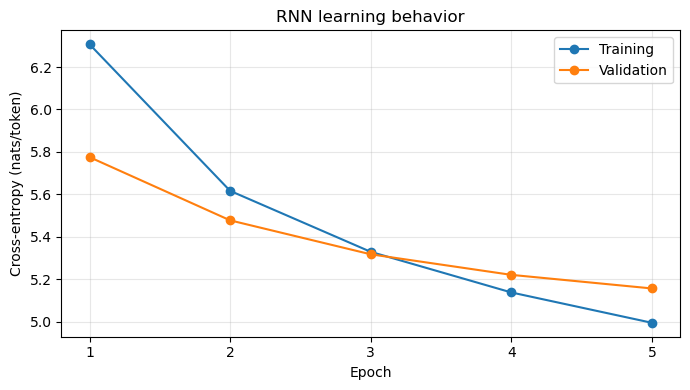

In [28]:
import matplotlib.pyplot as plt

rnn_dir = PROJECT_DIR / "results" / "rnn"
rnn_dir.mkdir(parents=True, exist_ok=True)

# Save the selected weights and training history.
torch.save(best_rnn_state, rnn_dir / "best_model.pt")

training_record = {
    "selected_epoch": best_rnn_epoch,
    "best_validation_cross_entropy": best_rnn_loss,
    "total_training_seconds": rnn_training_seconds,
    "embedding_dim": 100,
    "hidden_dim": 128,
    "learning_rate": 0.001,
    "history": rnn_history,
}

(rnn_dir / "training.json").write_text(
    json.dumps(training_record, indent=2),
    encoding="utf-8",
)

epochs = [row["epoch"] for row in rnn_history]

plt.figure(figsize=(7, 4))
plt.plot(
    epochs,
    [row["train_loss"] for row in rnn_history],
    marker="o",
    label="Training",
)
plt.plot(
    epochs,
    [row["validation_loss"] for row in rnn_history],
    marker="o",
    label="Validation",
)

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy (nats/token)")
plt.title("RNN learning behavior")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(rnn_dir / "loss_curve.png", dpi=300)
plt.show()

In [29]:
# Each appended row represents another completed training pass.
for actual_epoch, row in enumerate(rnn_history, start=1):
    row["epoch"] = actual_epoch

best_row = min(
    rnn_history,
    key=lambda row: row["validation_loss"],
)

best_rnn_epoch = best_row["epoch"]
best_rnn_loss = best_row["validation_loss"]

print("Actual training passes:", len(rnn_history))
print("Selected epoch:", best_rnn_epoch)

Actual training passes: 5
Selected epoch: 5


### 1.4.6 Test prediction quality
We choose the epoch 5 and valuate the restored best checkpoint using the same targets as the n-gram model.

In [30]:
test_loader = DataLoader(
    NewsLanguageDataset(encoded["test"]["input_ids"]),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_news,
)

rnn_test_metrics = run_language_epoch(rnn_model, test_loader)
rnn_test_ce = rnn_test_metrics["cross_entropy"]
rnn_test_ppl = math.exp(rnn_test_ce)

print(f"Test cross-entropy: {rnn_test_ce:.4f}")
print(f"Test perplexity: {rnn_test_ppl:.2f}")
print("Test prediction targets:", rnn_test_metrics["target_tokens"])

Test cross-entropy: 5.1501
Test perplexity: 172.45
Test prediction targets: 344472


### 1.4.7 Inference speed measurement
This following section measures how quickly the RNN predicts the next token. We reuse the same 100 prefixes as the n-gram model so the workload is consistent. 

In [31]:
def benchmark_neural_inference(neural_model, contexts):
    neural_model.eval()

    # Prepare inputs before timing.
    prepared_inputs = [
        torch.tensor(
            context,
            dtype=torch.long,
            device=device,
        ).unsqueeze(0)
        for context in contexts
    ]

    def predict_next(inputs):
        logits = neural_model(inputs)[0, -1, :]
        return torch.softmax(logits, dim=-1)

    with torch.no_grad():
        # Warm up the model and device.
        for inputs in prepared_inputs:
            predict_next(inputs)
        synchronize_device()

        timings = []

        for _ in range(3):
            synchronize_device()
            started = time.perf_counter()

            for inputs in prepared_inputs:
                predict_next(inputs)
                synchronize_device()

            timings.append(time.perf_counter() - started)

    median_seconds = statistics.median(timings)

    return {
        "inference_ms_per_prefix":
            1000 * median_seconds / len(contexts),
        "inference_prefixes_per_second":
            len(contexts) / median_seconds,
    }


rnn_inference = benchmark_neural_inference(
    rnn_model,
    timing_contexts,
)

print("Device:", device)
print(
    f"Inference latency: "
    f"{rnn_inference['inference_ms_per_prefix']:.3f} ms per prefix"
)
print(
    f"Inference throughput: "
    f"{rnn_inference['inference_prefixes_per_second']:.1f} "
    f"predictions per second"
)

Device: mps
Inference latency: 3.624 ms per prefix
Inference throughput: 275.9 predictions per second


### 1.4.8 Generated text

Generate continuations using the selected RNN checkpoint. The same prompts and decoding settings were applied as the n-gram model.

Compare whether the text forms sensible phrases, stays on topic, repeats tokens, produces unknown tokens, or ends too early.

In [32]:
import random


def generate_neural(neural_model, prompt, seed):
    neural_model.eval()

    # Remove <eos> so the model can continue the prompt.
    history = encode_text(prompt, token_to_id)[:-1]
    generated = []
    rng = random.Random(seed)

    with torch.no_grad():
        for _ in range(MAX_NEW_TOKENS):
            inputs = torch.tensor(
                [history],
                dtype=torch.long,
                device=device,
            )

            # Use the final position to predict the next token.
            logits = neural_model(inputs)[0, -1, :]

            # Sample from the top-k tokens.
            top_logits, top_ids = torch.topk(
                logits,
                k=min(TOP_K, len(PREDICTABLE_IDS)),
            )

            probabilities = torch.softmax(
                top_logits / TEMPERATURE,
                dim=-1,
            )

            next_id = rng.choices(
                top_ids.cpu().tolist(),
                weights=probabilities.cpu().tolist(),
                k=1,
            )[0]

            generated.append(next_id)

            if next_id == EOS_ID:
                break

            history.append(next_id)

    return decode_ids(generated, id_to_token)


rnn_examples = []

for index, prompt in enumerate(PROMPTS):
    continuation = generate_neural(
        rnn_model,
        prompt,
        seed=SEED + index,
    )

    rnn_examples.append({
        "prompt": prompt,
        "tokens": continuation,
    })

    print(f"\nPrompt: {prompt}")
    print("Continuation:", " ".join(continuation))


Prompt: the government
Continuation: ' s top coach of <unk> - based technology ( afp ) afp - <unk> - - microsoft corp . on friday said it must say they're good - to - peer - up state - rich <unk> - -

Prompt: the company
Continuation: ' s <unk> , the two - day before the team ' s biggest retailer said they . <eos>

Prompt: the team
Continuation: <unk> <unk> <unk> of more <unk> <unk> to the <unk> " and other staff <eos>


### 1.4.9 Results summary - RNN

In [33]:
rnn_result = {
    "model": "RNN",
    "seed": SEED,
    "device": str(device),

    # Prediction quality.
    "test_cross_entropy": rnn_test_ce,
    "test_perplexity": rnn_test_ppl,
    "test_target_tokens": rnn_test_metrics["target_tokens"],

    # Training and model cost.
    "training_seconds": rnn_training_seconds,
    "completed_epochs": len(rnn_history),
    "selected_epoch": best_rnn_epoch,
    "trainable_parameters": sum(
        parameter.numel()
        for parameter in rnn_model.parameters()
        if parameter.requires_grad
    ),
    "stored_model_size_mib": (
        (rnn_dir / "best_model.pt").stat().st_size / (1024 ** 2)
    ),

    # Inference speed and generated text.
    **rnn_inference,
    "generated_examples": rnn_examples,
}

results_path = rnn_dir / "metrics.json"
results_path.write_text(
    json.dumps(rnn_result, indent=2),
    encoding="utf-8",
)

print(f"Test cross-entropy: {rnn_test_ce:.4f}")
print(f"Test perplexity: {rnn_test_ppl:.2f}")
print(f"Training time: {rnn_training_seconds:.1f} seconds")
print("Completed epochs:", rnn_result["completed_epochs"])
print("Selected epoch:", best_rnn_epoch)
print(f"Trainable parameters: {rnn_result['trainable_parameters']:,}")
print(
    f"Stored model size: "
    f"{rnn_result['stored_model_size_mib']:.2f} MiB"
)
print("Saved results to:", results_path)

Test cross-entropy: 5.1501
Test perplexity: 172.45
Training time: 367.9 seconds
Completed epochs: 5
Selected epoch: 5
Trainable parameters: 2,319,440
Stored model size: 8.85 MiB
Saved results to: /Users/caleb/Desktop/DSA4213/Assignment_1/results/rnn/metrics.json


### 1.5 LSTM
The LSTM uses a cell state and gates to control how information is
retained and updated across a sequence.

We keep the same dataset, vocabulary, 100-dimensional trainable embeddings,
128 hidden units, and one forward-only recurrent layer as the RNN.
The LSTM has more parameters because of its gates; we report this difference.

### 1.5.1 Define and check the LSTM

Token IDs → learned embeddings → LSTM hidden states → next-token scores.
Padding targets are ignored, and <pad> and <bos> cannot be predicted.

In [34]:
class LSTMLanguageModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim=100, hidden_dim=128):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=PAD_ID,
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True,
            bidirectional=False,
        )

        self.output_layer = nn.Linear(hidden_dim, vocab_size)

    def forward(self, input_ids):
        embeddings = self.embedding(input_ids)

        # The LSTM returns outputs plus its final hidden and cell states.
        hidden_states, _ = self.lstm(embeddings)
        logits = self.output_layer(hidden_states)

        logits[..., PAD_ID] = float("-inf")
        logits[..., BOS_ID] = float("-inf")

        return logits


torch.manual_seed(SEED)

lstm_model = LSTMLanguageModel(
    vocab_size=len(id_to_token),
).to(device)

# Use a validation batch for this check.
example_inputs, example_targets = next(iter(validation_loader))

lstm_model.eval()

with torch.no_grad():
    example_logits = lstm_model(example_inputs.to(device))

    initial_loss = criterion(
        example_logits.reshape(-1, len(id_to_token)),
        example_targets.to(device).reshape(-1),
    )

lstm_parameter_count = sum(
    parameter.numel()
    for parameter in lstm_model.parameters()
    if parameter.requires_grad
)

print("Input shape:", example_inputs.shape)
print("Output shape:", example_logits.shape)
print(f"Trainable parameters: {lstm_parameter_count:,}")
print(f"Initial cross-entropy: {initial_loss.item():.4f}")

Input shape: torch.Size([32, 63])
Output shape: torch.Size([32, 63, 10000])
Trainable parameters: 2,407,760
Initial cross-entropy: 9.2117


### 1.5.2 Train and select the best checkpoint

Train for five epochs using Adam with learning rate 0.001 and
gradient clipping at 1.0, matching the RNN training settings.

Record training and validation cross-entropy after each epoch.
Select the checkpoint with the lowest validation cross-entropy.
Training time excludes validation and checkpoint copying.

This cell initializes a fresh model, optimizer, and training history.

In [35]:
LSTM_EPOCHS = 5

# Start a fresh experiment whenever this cell runs.
torch.manual_seed(SEED)

lstm_model = LSTMLanguageModel(
    vocab_size=len(id_to_token),
).to(device)

lstm_optimizer = torch.optim.Adam(
    lstm_model.parameters(),
    lr=0.001,
)

# Give this experiment its own reproducible training shuffle.
lstm_train_loader = DataLoader(
    NewsLanguageDataset(train_sequences),
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_news,
    generator=torch.Generator().manual_seed(SEED),
)

lstm_history = []
best_lstm_loss = float("inf")
best_lstm_epoch = None
best_lstm_state = None

for epoch in range(1, LSTM_EPOCHS + 1):
    # Measure training time separately from validation.
    synchronize_device()
    started = time.perf_counter()

    train_metrics = run_language_epoch(
        lstm_model,
        lstm_train_loader,
        optimizer=lstm_optimizer,
    )

    synchronize_device()
    epoch_seconds = time.perf_counter() - started

    validation_metrics = run_language_epoch(
        lstm_model,
        validation_loader,
    )

    lstm_history.append({
        "epoch": epoch,
        "train_loss": train_metrics["cross_entropy"],
        "validation_loss": validation_metrics["cross_entropy"],
        "training_seconds": epoch_seconds,
    })

    # Keep an independent copy of the best checkpoint.
    if validation_metrics["cross_entropy"] < best_lstm_loss:
        best_lstm_loss = validation_metrics["cross_entropy"]
        best_lstm_epoch = epoch

        best_lstm_state = {
            name: tensor.detach().cpu().clone()
            for name, tensor in lstm_model.state_dict().items()
        }

    print(
        f"\nEpoch {epoch} | "
        f"Train CE: {train_metrics['cross_entropy']:.4f} | "
        f"Validation CE: {validation_metrics['cross_entropy']:.4f} | "
        f"Training: {epoch_seconds:.1f}s"
    )

# Use the best validation checkpoint for evaluation.
lstm_model.load_state_dict(best_lstm_state)
lstm_model.eval()

lstm_training_seconds = sum(
    row["training_seconds"] for row in lstm_history
)

print("\nRecorded epochs:", [row["epoch"] for row in lstm_history])
print("Selected epoch:", best_lstm_epoch)
print(f"Best validation CE: {best_lstm_loss:.4f}")
print(f"Total training time: {lstm_training_seconds:.1f} seconds")

Batch 100/625 | Running CE: 7.3137
Batch 200/625 | Running CE: 6.9585
Batch 300/625 | Running CE: 6.7804
Batch 400/625 | Running CE: 6.6547
Batch 500/625 | Running CE: 6.5608
Batch 600/625 | Running CE: 6.4818

Epoch 1 | Train CE: 6.4632 | Validation CE: 5.9599 | Training: 42.8s
Batch 100/625 | Running CE: 5.9611
Batch 200/625 | Running CE: 5.9395
Batch 300/625 | Running CE: 5.9042
Batch 400/625 | Running CE: 5.8761
Batch 500/625 | Running CE: 5.8491
Batch 600/625 | Running CE: 5.8272

Epoch 2 | Train CE: 5.8203 | Validation CE: 5.6433 | Training: 34.7s
Batch 100/625 | Running CE: 5.6140
Batch 200/625 | Running CE: 5.6050
Batch 300/625 | Running CE: 5.5898
Batch 400/625 | Running CE: 5.5756
Batch 500/625 | Running CE: 5.5611
Batch 600/625 | Running CE: 5.5477

Epoch 3 | Train CE: 5.5442 | Validation CE: 5.4627 | Training: 33.3s
Batch 100/625 | Running CE: 5.3845
Batch 200/625 | Running CE: 5.3819
Batch 300/625 | Running CE: 5.3743
Batch 400/625 | Running CE: 5.3675
Batch 500/625 | Runn

### 1.5.3 Learning curves and saved checkpoint

Plot training and validation cross-entropy to examine learning progress
and any gap between training and validation performance.

Save the checkpoint selected using validation loss and its training history.

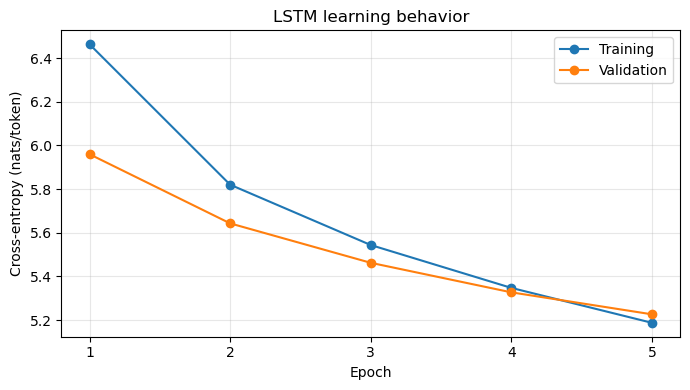

In [36]:
lstm_dir = PROJECT_DIR / "results" / "lstm"
lstm_dir.mkdir(parents=True, exist_ok=True)

torch.save(best_lstm_state, lstm_dir / "best_model.pt")

lstm_training_record = {
    "seed": SEED,
    "device": str(device),
    "completed_epochs": len(lstm_history),
    "selected_epoch": best_lstm_epoch,
    "best_validation_cross_entropy": best_lstm_loss,
    "total_training_seconds": lstm_training_seconds,
    "embedding_dim": 100,
    "hidden_dim": 128,
    "learning_rate": 0.001,
    "history": lstm_history,
}

(lstm_dir / "training.json").write_text(
    json.dumps(lstm_training_record, indent=2),
    encoding="utf-8",
)

epochs = [row["epoch"] for row in lstm_history]

plt.figure(figsize=(7, 4))
plt.plot(
    epochs,
    [row["train_loss"] for row in lstm_history],
    marker="o",
    label="Training",
)
plt.plot(
    epochs,
    [row["validation_loss"] for row in lstm_history],
    marker="o",
    label="Validation",
)

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy (nats/token)")
plt.title("LSTM learning behavior")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(lstm_dir / "loss_curve.png", dpi=300)
plt.show()

### 1.5.4 Test prediction quality

Evaluate the selected LSTM checkpoint on the same test sequences
and prediction targets used by the other language models.

In [37]:
lstm_test_metrics = run_language_epoch(
    lstm_model,
    test_loader,
)

lstm_test_ce = lstm_test_metrics["cross_entropy"]
lstm_test_ppl = math.exp(lstm_test_ce)

print(f"Test cross-entropy: {lstm_test_ce:.4f}")
print(f"Test perplexity: {lstm_test_ppl:.2f}")
print("Test prediction targets:", lstm_test_metrics["target_tokens"])

Test cross-entropy: 5.2179
Test perplexity: 184.54
Test prediction targets: 344472


### 1.5.5 Inference speed

Measure the selected LSTM on the same validation prefixes and timing
procedure used for the RNN and n-gram model.

In [38]:
lstm_inference = benchmark_neural_inference(
    lstm_model,
    timing_contexts,
)

print("Device:", device)
print(
    f"Inference latency: "
    f"{lstm_inference['inference_ms_per_prefix']:.3f} ms per prefix"
)
print(
    f"Inference throughput: "
    f"{lstm_inference['inference_prefixes_per_second']:.1f} "
    f"predictions per second"
)

Device: mps
Inference latency: 0.926 ms per prefix
Inference throughput: 1079.5 predictions per second


### 1.5.6 Generated text

Generate continuations using the same prompts, sampling seeds,
top-50 sampling, temperature 1, and maximum of 40 new tokens.

Compare phrase quality, topic consistency, repetition, unknown tokens,
and early termination with the other models.

In [39]:
lstm_examples = []

for index, prompt in enumerate(PROMPTS):
    continuation = generate_neural(
        lstm_model,
        prompt,
        seed=SEED + index,
    )

    lstm_examples.append({
        "prompt": prompt,
        "tokens": continuation,
    })

    print(f"\nPrompt: {prompt}")
    print("Continuation:", " ".join(continuation))


Prompt: the government
Continuation: ' s top ceo <unk> <unk> a group , has filed in an israeli - par <unk> the season for <unk> with the first second team on with a <unk> - 1 win over at <unk> , <unk> - <unk>

Prompt: the company
Continuation: ' s <unk> ' s latest <unk> <unk> - - a <unk> in the first inning wednesday it will be out of the first half of their first inning , that has played one of the <eos>

Prompt: the team
Continuation: of <unk> <unk> , two the <unk> has agreed to find <unk> . by news - 1 . 1 0 . 5 . for <unk> <unk> on monday . <unk> <unk> park and the <unk> of a series of the


### 1.5.7 Save results

Save test prediction quality, training cost, model size, inference speed,
and generated examples for the final comparison.

In [40]:
lstm_result = {
    "model": "LSTM",
    "seed": SEED,
    "device": str(device),

    # Prediction quality.
    "test_cross_entropy": lstm_test_ce,
    "test_perplexity": lstm_test_ppl,
    "test_target_tokens": lstm_test_metrics["target_tokens"],

    # Training and model cost.
    "training_seconds": lstm_training_seconds,
    "completed_epochs": len(lstm_history),
    "selected_epoch": best_lstm_epoch,
    "trainable_parameters": sum(
        parameter.numel()
        for parameter in lstm_model.parameters()
        if parameter.requires_grad
    ),
    "stored_model_size_mib": (
        (lstm_dir / "best_model.pt").stat().st_size / (1024 ** 2)
    ),

    # Inference speed and generated text.
    **lstm_inference,
    "generated_examples": lstm_examples,
}

lstm_results_path = lstm_dir / "metrics.json"
lstm_results_path.write_text(
    json.dumps(lstm_result, indent=2),
    encoding="utf-8",
)

print(f"Test cross-entropy: {lstm_test_ce:.4f}")
print(f"Test perplexity: {lstm_test_ppl:.2f}")
print(f"Training time: {lstm_training_seconds:.1f} seconds")
print("Completed epochs:", lstm_result["completed_epochs"])
print("Selected epoch:", best_lstm_epoch)
print(f"Trainable parameters: {lstm_result['trainable_parameters']:,}")
print(
    f"Stored model size: "
    f"{lstm_result['stored_model_size_mib']:.2f} MiB"
)
print("Saved results to:", lstm_results_path)

Test cross-entropy: 5.2179
Test perplexity: 184.54
Training time: 185.4 seconds
Completed epochs: 5
Selected epoch: 5
Trainable parameters: 2,407,760
Stored model size: 9.19 MiB
Saved results to: /Users/caleb/Desktop/DSA4213/Assignment_1/results/lstm/metrics.json


## 1.6 Transformer language model

Next we are going to train a small causal Transformer from random initialization using
the same dataset, tokenizer, vocabulary, and prediction targets.

Configuration:
- 100-dimensional trainable token embeddings.
- Sinusoidal positional encoding to represent token order.
- Two Transformer layers, each with four attention heads.
- Feedforward dimension of 256.
- Dropout of 0, matching the absence of dropout in our RNN and LSTM.

A causal mask prevents attention to future tokens. A padding mask
prevents attention to padding. Model sizes differ across architectures
and will be reported in the comparison.

### 1.6.1 Define the Transformer

In [41]:
class TransformerLanguageModel(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=100,
        num_heads=4,
        num_layers=2,
        feedforward_dim=256,
    ):
        super().__init__()

        self.embedding_dim = embedding_dim

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=PAD_ID,
        )

        # Fixed frequencies for sinusoidal positional encoding.
        self.register_buffer(
            "position_frequencies",
            torch.exp(
                torch.arange(0, embedding_dim, 2, dtype=torch.float32)
                * (-math.log(10000.0) / embedding_dim)
            ),
        )

        # Construct each layer separately for independent initialization.
        self.layers = nn.ModuleList([
            nn.TransformerEncoderLayer(
                d_model=embedding_dim,
                nhead=num_heads,
                dim_feedforward=feedforward_dim,
                dropout=0.0,
                activation="gelu",
                batch_first=True,
                norm_first=True,
            )
            for _ in range(num_layers)
        ])

        self.final_norm = nn.LayerNorm(embedding_dim)
        self.output_layer = nn.Linear(embedding_dim, vocab_size)

    def forward(self, input_ids):
        sequence_length = input_ids.size(1)

        hidden = (
            self.embedding(input_ids)
            * math.sqrt(self.embedding_dim)
        )

        # Create positional information for this sequence length.
        positions = torch.arange(
            sequence_length,
            device=input_ids.device,
            dtype=hidden.dtype,
        ).unsqueeze(1)

        angles = positions * self.position_frequencies.unsqueeze(0)

        positional_encoding = torch.zeros(
            sequence_length,
            self.embedding_dim,
            device=input_ids.device,
            dtype=hidden.dtype,
        )
        positional_encoding[:, 0::2] = torch.sin(angles)
        positional_encoding[:, 1::2] = torch.cos(angles)

        hidden = hidden + positional_encoding.unsqueeze(0)

        # True means attention to that position is blocked.
        causal_mask = torch.triu(
            torch.ones(
                sequence_length,
                sequence_length,
                device=input_ids.device,
                dtype=torch.bool,
            ),
            diagonal=1,
        )

        padding_mask = input_ids.eq(PAD_ID)

        for layer in self.layers:
            hidden = layer(
                hidden,
                src_mask=causal_mask,
                src_key_padding_mask=padding_mask,
            )

        logits = self.output_layer(self.final_norm(hidden))

        logits[..., PAD_ID] = float("-inf")
        logits[..., BOS_ID] = float("-inf")

        return logits

### 1.6.2 Check output shape and causality

Check that each input position produces vocabulary-sized scores.

To check causality, change tokens after the fourth position.
Predictions at the first four positions should remain unchanged,
because those positions cannot attend to the modified future tokens.

In [42]:
torch.manual_seed(SEED)

transformer_model = TransformerLanguageModel(
    vocab_size=len(id_to_token),
).to(device)

example_inputs, example_targets = next(iter(validation_loader))

transformer_model.eval()

with torch.no_grad():
    example_logits = transformer_model(example_inputs.to(device))

    initial_loss = criterion(
        example_logits.reshape(-1, len(id_to_token)),
        example_targets.to(device).reshape(-1),
    )

    # Change only the future portion of one short sequence.
    original = example_inputs[:1, :8].clone().to(device)
    modified = original.clone()
    modified[:, 4:] = UNK_ID

    original_logits = transformer_model(original)
    modified_logits = transformer_model(modified)

    # Compare permitted predictions at the unchanged first four positions.
    torch.testing.assert_close(
        original_logits[:, :4, PREDICTABLE_IDS],
        modified_logits[:, :4, PREDICTABLE_IDS],
        atol=1e-5,
        rtol=1e-5,
    )

transformer_parameter_count = sum(
    parameter.numel()
    for parameter in transformer_model.parameters()
    if parameter.requires_grad
)

print("Input shape:", example_inputs.shape)
print("Output shape:", example_logits.shape)
print(f"Trainable parameters: {transformer_parameter_count:,}")
print(f"Initial cross-entropy: {initial_loss.item():.4f}")
print("Causal check passed.")

Input shape: torch.Size([32, 63])
Output shape: torch.Size([32, 63, 10000])
Trainable parameters: 2,194,912
Initial cross-entropy: 9.3541
Causal check passed.


### 1.6.3 Train and select the best checkpoint

Train the Transformer for five epochs and select the checkpoint with
the lowest validation cross-entropy.

Use the same optimizer, learning rate, batch size, and gradient clipping
as the other neural models. Training time excludes validation and
checkpoint copying.

This cell starts a fresh model, optimizer, and training history.

In [43]:
TRANSFORMER_EPOCHS = 5

TRANSFORMER_CONFIG = {
    "embedding_dim": 100,
    "num_heads": 4,
    "num_layers": 2,
    "feedforward_dim": 256,
}

# Start a fresh experiment whenever this cell runs.
torch.manual_seed(SEED)

transformer_model = TransformerLanguageModel(
    vocab_size=len(id_to_token),
    **TRANSFORMER_CONFIG,
).to(device)

transformer_optimizer = torch.optim.Adam(
    transformer_model.parameters(),
    lr=0.001,
)

transformer_train_loader = DataLoader(
    NewsLanguageDataset(train_sequences),
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_news,
    generator=torch.Generator().manual_seed(SEED),
)

transformer_history = []
best_transformer_loss = float("inf")
best_transformer_epoch = None
best_transformer_state = None

for epoch in range(1, TRANSFORMER_EPOCHS + 1):
    synchronize_device()
    started = time.perf_counter()

    train_metrics = run_language_epoch(
        transformer_model,
        transformer_train_loader,
        optimizer=transformer_optimizer,
    )

    synchronize_device()
    epoch_seconds = time.perf_counter() - started

    validation_metrics = run_language_epoch(
        transformer_model,
        validation_loader,
    )

    transformer_history.append({
        "epoch": epoch,
        "train_loss": train_metrics["cross_entropy"],
        "validation_loss": validation_metrics["cross_entropy"],
        "training_seconds": epoch_seconds,
    })

    if validation_metrics["cross_entropy"] < best_transformer_loss:
        best_transformer_loss = validation_metrics["cross_entropy"]
        best_transformer_epoch = epoch

        best_transformer_state = {
            name: tensor.detach().cpu().clone()
            for name, tensor in transformer_model.state_dict().items()
        }

    print(
        f"\nEpoch {epoch} | "
        f"Train CE: {train_metrics['cross_entropy']:.4f} | "
        f"Validation CE: {validation_metrics['cross_entropy']:.4f} | "
        f"Training: {epoch_seconds:.1f}s"
    )

# Restore the checkpoint selected using validation loss.
transformer_model.load_state_dict(best_transformer_state)
transformer_model.eval()

transformer_training_seconds = sum(
    row["training_seconds"] for row in transformer_history
)

print(
    "\nRecorded epochs:",
    [row["epoch"] for row in transformer_history],
)
print("Selected epoch:", best_transformer_epoch)
print(f"Best validation CE: {best_transformer_loss:.4f}")
print(f"Total training time: {transformer_training_seconds:.1f} seconds")

Batch 100/625 | Running CE: 7.4516
Batch 200/625 | Running CE: 6.9716
Batch 300/625 | Running CE: 6.7246
Batch 400/625 | Running CE: 6.5616
Batch 500/625 | Running CE: 6.4435
Batch 600/625 | Running CE: 6.3482

Epoch 1 | Train CE: 6.3263 | Validation CE: 5.7437 | Training: 77.4s
Batch 100/625 | Running CE: 5.6733
Batch 200/625 | Running CE: 5.6556
Batch 300/625 | Running CE: 5.6249
Batch 400/625 | Running CE: 5.6012
Batch 500/625 | Running CE: 5.5781
Batch 600/625 | Running CE: 5.5594

Epoch 2 | Train CE: 5.5541 | Validation CE: 5.4595 | Training: 108.4s
Batch 100/625 | Running CE: 5.2813
Batch 200/625 | Running CE: 5.2821
Batch 300/625 | Running CE: 5.2784
Batch 400/625 | Running CE: 5.2714
Batch 500/625 | Running CE: 5.2632
Batch 600/625 | Running CE: 5.2576

Epoch 3 | Train CE: 5.2555 | Validation CE: 5.3246 | Training: 134.6s
Batch 100/625 | Running CE: 5.0423
Batch 200/625 | Running CE: 5.0513
Batch 300/625 | Running CE: 5.0558
Batch 400/625 | Running CE: 5.0579
Batch 500/625 | Ru

### 1.6.4 Learning curves and saved checkpoint

Plot training and validation cross-entropy to examine learning progress.
Save the checkpoint selected using validation loss and its training history.

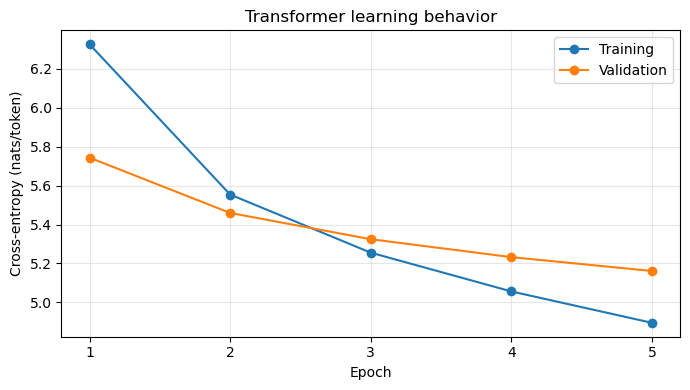

In [44]:
transformer_dir = PROJECT_DIR / "results" / "transformer"
transformer_dir.mkdir(parents=True, exist_ok=True)

torch.save(
    best_transformer_state,
    transformer_dir / "best_model.pt",
)

transformer_training_record = {
    "seed": SEED,
    "device": str(device),
    "completed_epochs": len(transformer_history),
    "selected_epoch": best_transformer_epoch,
    "best_validation_cross_entropy": best_transformer_loss,
    "total_training_seconds": transformer_training_seconds,
    "model_config": TRANSFORMER_CONFIG,
    "dropout": 0.0,
    "learning_rate": 0.001,
    "batch_size": BATCH_SIZE,
    "history": transformer_history,
}

(transformer_dir / "training.json").write_text(
    json.dumps(transformer_training_record, indent=2),
    encoding="utf-8",
)

epochs = [row["epoch"] for row in transformer_history]

plt.figure(figsize=(7, 4))
plt.plot(
    epochs,
    [row["train_loss"] for row in transformer_history],
    marker="o",
    label="Training",
)
plt.plot(
    epochs,
    [row["validation_loss"] for row in transformer_history],
    marker="o",
    label="Validation",
)

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy (nats/token)")
plt.title("Transformer learning behavior")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(transformer_dir / "loss_curve.png", dpi=300)
plt.show()

### 1.6.5 Test prediction quality

Evaluate the selected Transformer checkpoint on the same test sequences
and prediction targets used by the other language models.

In [45]:
transformer_test_metrics = run_language_epoch(
    transformer_model,
    test_loader,
)

transformer_test_ce = transformer_test_metrics["cross_entropy"]
transformer_test_ppl = math.exp(transformer_test_ce)

print(f"Test cross-entropy: {transformer_test_ce:.4f}")
print(f"Test perplexity: {transformer_test_ppl:.2f}")
print(
    "Test prediction targets:",
    transformer_test_metrics["target_tokens"],
)

Test cross-entropy: 5.1561
Test perplexity: 173.48
Test prediction targets: 344472


### 1.6.6 Inference speed

Measure the selected Transformer using the same validation prefixes
and timing procedure as the other models.

In [46]:
transformer_inference = benchmark_neural_inference(
    transformer_model,
    timing_contexts,
)

print("Device:", device)
print(
    f"Inference latency: "
    f"{transformer_inference['inference_ms_per_prefix']:.3f} "
    f"ms per prefix"
)
print(
    f"Inference throughput: "
    f"{transformer_inference['inference_prefixes_per_second']:.1f} "
    f"predictions per second"
)

Device: mps
Inference latency: 23.664 ms per prefix
Inference throughput: 42.3 predictions per second


### 1.6.7 Generated text

Use the same prompts, sampling seeds, top-50 sampling, temperature 1,
and maximum of 40 new tokens as the other models.

Compare phrase quality, topic consistency, repetition, unknown tokens,
and early termination.

In [47]:
transformer_examples = []

for index, prompt in enumerate(PROMPTS):
    continuation = generate_neural(
        transformer_model,
        prompt,
        seed=SEED + index,
    )

    transformer_examples.append({
        "prompt": prompt,
        "tokens": continuation,
    })

    print(f"\nPrompt: {prompt}")
    print("Continuation:", " ".join(continuation))


Prompt: the government
Continuation: ' s president michael owen is in a key role against their third in the international space for a lot . the world cup teammates at his five minutes of the yankees . <eos>

Prompt: the company
Continuation: ' s <unk> . com bank of the network , research ) will have <unk> at work when the company are the world's largest bank of his own pcs , for their decision after the united states . with the

Prompt: the team
Continuation: report of <unk> the head coach tyrone willingham . . this morning after receiving by <unk> , he is returning to a 2 seconds remaining <unk> at the season with a first win the season . <eos>


### 1.6.8 Save results

Save the selected Transformer's prediction quality, training cost,
model size, inference speed, and generated examples.

In [48]:
transformer_result = {
    "model": "Transformer",
    "seed": SEED,
    "device": str(device),
    "model_config": TRANSFORMER_CONFIG,

    "test_cross_entropy": transformer_test_ce,
    "test_perplexity": transformer_test_ppl,
    "test_target_tokens": transformer_test_metrics["target_tokens"],

    "training_seconds": transformer_training_seconds,
    "completed_epochs": len(transformer_history),
    "selected_epoch": best_transformer_epoch,
    "trainable_parameters": sum(
        parameter.numel()
        for parameter in transformer_model.parameters()
        if parameter.requires_grad
    ),
    "stored_model_size_mib": (
        (transformer_dir / "best_model.pt").stat().st_size
        / (1024 ** 2)
    ),

    **transformer_inference,
    "generated_examples": transformer_examples,
}

(transformer_dir / "metrics.json").write_text(
    json.dumps(transformer_result, indent=2),
    encoding="utf-8",
)

print(
    f"Stored model size: "
    f"{transformer_result['stored_model_size_mib']:.2f} MiB"
)
print("Saved Transformer results.")

Stored model size: 8.38 MiB
Saved Transformer results.


## 1.7 Compare the four language models

Compare test prediction quality, training cost, model size, and
inference speed using the measurements from this experiment.

All models use the same data, vocabulary, and prediction targets.
Neural models receive five training epochs.

Inference uses the same 100 prefixes and produces a full next-token
distribution per request. Neural models recompute each complete prefix;
this measures our implementation without cached generation.

In [49]:
import pandas as pd

all_results = [
    ngram_result,
    rnn_result,
    lstm_result,
    transformer_result,
]

comparison = pd.DataFrame([
    {
        "Model": result["model"],
        "Test CE": result["test_cross_entropy"],
        "Test perplexity": result["test_perplexity"],
        "Training seconds": result["training_seconds"],
        "Trainable parameters": (
            f"{result['trainable_parameters']:,}"
            if "trainable_parameters" in result
            else "N/A — count tables"
        ),
        "Stored size MiB": result["stored_model_size_mib"],
        "Device": result.get("device", "cpu"),
        "Latency ms": result["inference_ms_per_prefix"],
        "Predictions per second": result["inference_prefixes_per_second"],
    }
    for result in all_results
])

print("Prediction quality and training cost")
display(comparison[[
    "Model",
    "Test CE",
    "Test perplexity",
    "Training seconds",
    "Trainable parameters",
    "Stored size MiB",
]].round(3))

print("Inference speed")
display(comparison[[
    "Model",
    "Device",
    "Latency ms",
    "Predictions per second",
]].round(3))

# Save the comparison and the current results for all four models.
comparison.to_csv(
    PROJECT_DIR / "results" / "part1_comparison.csv",
    index=False,
)

for folder, result in zip(
    ["ngram", "rnn", "lstm", "transformer"],
    all_results,
):
    result_dir = PROJECT_DIR / "results" / folder
    result_dir.mkdir(parents=True, exist_ok=True)

    (result_dir / "metrics.json").write_text(
        json.dumps(result, indent=2),
        encoding="utf-8",
    )

Prediction quality and training cost


,Model,Test CE,Test perplexity,Training seconds,Trainable parameters,Stored size MiB
0,N-gram,5.091,162.589,1.212,N/A — count tables,11.624
1,RNN,5.150,172.448,367.896,"2,319,440",8.851
2,LSTM,5.218,184.540,185.395,"2,407,760",9.188
3,Transformer,5.156,173.482,588.667,"2,194,912",8.382


Inference speed


,Model,Device,Latency ms,Predictions per second
0,N-gram,cpu,6.748,148.198
1,RNN,mps,3.624,275.950
2,LSTM,mps,0.926,1079.524
3,Transformer,mps,23.664,42.258


**Prediction quality.** The interpolated n-gram model achieved the lowest test perplexity (162.589), followed by the RNN (172.448), Transformer (173.482), and LSTM (184.540). The RNN and Transformer performed similarly and LSTM performs the worst in this context. The observed strong n-gram may be due to that recurring local phrases in news text benefit count-based prediction, while the neural models received a limited training budget in this context. In addtion, since we used a small training set, the extra parameters in neural models become a liability.

**Training cost and model size.** N-gram counting took 1.212 seconds. Among neural models, the LSTM trained fastest (185.395 seconds), followed by the RNN (367.896 seconds) and Transformer (588.667 seconds). All neural models received five epochs, but their computation costs differed. The Transformer had the fewest trainable parameters (2,194,912) and smallest saved checkpoint (8.382 MiB). The n-gram count tables occupied 11.624 MiB. These sizes measure serialized artifacts, not runtime memory.

**Inference cost.** For the measured workload, the LSTM achieved the lowest latency at 0.93 ms per prefix, followed by the RNN (3.62 ms), n-gram model (6.75 ms), and Transformer (23.66 ms). Corresponding throughputs were approximately 1,079.5, 275.9, 148.2, and 42.3 predictions per second. 

**Learning behavior.** Validation cross-entropy decreased across all five epochs, reaching 5.150 for the RNN, 5.218 for the LSTM, and 5.156 for the Transformer. At epoch 5, validation loss exceeded training loss by approximately 0.162, 0.039, and 0.266, respectively. The LSTM had both higher training and validation loss, so its weaker test result cannot be attributed to greater overfitting from these curves. 

# Part 2: Embedding Variants and Ablation

## 2.1 Architecture selection and experimental design

We select the RNN to investigate the effect of input embeddings. Its validation cross-entropy (5.150) was approximately equal to the Transformer’s (5.156), while its measured training time was lower. Although the LSTM trained faster, it had higher validation cross-entropy (5.218). These results support the RNN as a practical baseline without establishing general architectural superiority.

The RNN’s 100-dimensional input embeddings also match the public embeddings selected for this comparison. We reuse the Part I RNN as the random, trainable embedding baseline. Two fresh RNNs will use separately trained CBOW embeddings and public GloVe embeddings, respectively.

Across settings, we retain the same vocabulary, data splits, embedding dimension, recurrent architecture, and language-model training procedure.

## 2.2 Fixed settings and baseline reuse

All three language-model settings use 100-dimensional embeddings,
128 RNN hidden units, one forward-only recurrent layer, batch size 32,
Adam with learning rate 0.001, gradient clipping at 1.0, and five epochs.

Select checkpoints using validation cross-entropy.
Reuse the Part I tokenizer, vocabulary, splits, and evaluation functions.

CBOW embedding training has its own separately reported budget.

In [50]:
PART2_LM_CONFIG = {
    "embedding_dim": 100,
    "hidden_dim": 128,
    "epochs": 5,
    "batch_size": 32,
    "learning_rate": 0.001,
    "gradient_clip": 1.0,
    "seed": SEED,
}

CBOW_CONFIG = {
    "embedding_dim": 100,
    "window": 2,          # Up to two words on either side.
    "epochs": 3,          # Separate embedding-training budget.
    "batch_size": 256,
    "learning_rate": 0.001,
    "seed": SEED,
}

PUBLIC_EMBEDDING = "GloVe 6B Wikipedia 2014 + Gigaword 5, 100d"

# Check that the existing RNN matches our comparison.
assert rnn_model.embedding.embedding_dim == 100
assert rnn_model.rnn.hidden_size == 128
assert rnn_model.rnn.num_layers == 1
assert not rnn_model.rnn.bidirectional
assert rnn_model.embedding.weight.requires_grad
assert [row["epoch"] for row in rnn_history] == [1, 2, 3, 4, 5]
assert BATCH_SIZE == PART2_LM_CONFIG["batch_size"]
assert rnn_optimizer.param_groups[0]["lr"] == 0.001

# Keep a separate result dictionary for Part II.
part2_baseline = {
    **rnn_result,
    "embedding_setting": "Random/trainable",
    "embedding_training_seconds": 0.0,
}

# Remove boundary markers for the separate word-embedding task.
# Use only training text; labels are not used.
embedding_sequences = [
    sequence[1:-1]
    for sequence in train_sequences
    if len(sequence[1:-1]) >= 2
]

print("Baseline checks passed.")
print(
    f"Reused baseline test perplexity: "
    f"{part2_baseline['test_perplexity']:.2f}"
)
print("Embedding dimension:", PART2_LM_CONFIG["embedding_dim"])
print("Training news items usable for CBOW:", len(embedding_sequences))
print(
    "Training tokens usable for CBOW:",
    sum(len(sequence) for sequence in embedding_sequences),
)
print("Public embeddings:", PUBLIC_EMBEDDING)

Baseline checks passed.
Reused baseline test perplexity: 172.45
Embedding dimension: 100
Training news items usable for CBOW: 20000
Training tokens usable for CBOW: 892040
Public embeddings: GloVe 6B Wikipedia 2014 + Gigaword 5, 100d


## 2.3 Train the CBOW embeddings

We train 100-dimensional embeddings using only the training corpus.

For each centre token, use up to two neighbouring tokens on each side.
Contexts never cross news-item boundaries. Missing context positions
at the beginning or end of an item are padded and excluded from averaging.

CBOW learns embeddings by predicting the centre token from the mean
of its context embeddings. This is separate from RNN language-model training.

### 2.3.1 Prepare context–target examples

In [51]:
from torch.utils.data import TensorDataset

preparation_started = time.perf_counter()

window = CBOW_CONFIG["window"]
num_examples = sum(len(sequence) for sequence in embedding_sequences)

# Allocate tensors once, rather than storing many small Python objects.
cbow_contexts = torch.full(
    (num_examples, 2 * window),
    PAD_ID,
    dtype=torch.long,
)
cbow_targets = torch.empty(num_examples, dtype=torch.long)

offsets = torch.tensor(
    [offset for offset in range(-window, window + 1) if offset != 0],
    dtype=torch.long,
)

cursor = 0

for sequence in embedding_sequences:
    token_ids = torch.tensor(sequence, dtype=torch.long)
    length = len(sequence)

    # Each row contains neighbouring positions for one centre token.
    positions = torch.arange(length).unsqueeze(1) + offsets
    valid_positions = (positions >= 0) & (positions < length)

    # Clamp only to make indexing safe; invalid positions become padding.
    contexts = token_ids[positions.clamp(0, length - 1)]
    contexts = contexts.masked_fill(~valid_positions, PAD_ID)

    cbow_contexts[cursor:cursor + length] = contexts
    cbow_targets[cursor:cursor + length] = token_ids
    cursor += length

assert cursor == num_examples
assert cbow_contexts.ne(PAD_ID).any(dim=1).all()

cbow_preparation_seconds = time.perf_counter() - preparation_started

cbow_dataset = TensorDataset(cbow_contexts, cbow_targets)

cbow_loader = DataLoader(
    cbow_dataset,
    batch_size=CBOW_CONFIG["batch_size"],
    shuffle=True,
    generator=torch.Generator().manual_seed(CBOW_CONFIG["seed"]),
)

print("Context shape:", cbow_contexts.shape)
print("Target shape:", cbow_targets.shape)
print("Batches per epoch:", len(cbow_loader))
print(f"Example preparation: {cbow_preparation_seconds:.2f} seconds")

for index in range(3):
    context_tokens = decode_ids(
        cbow_contexts[index].tolist(),
        id_to_token,
    )
    target_token = id_to_token[cbow_targets[index].item()]

    print(f"\nContext: {' '.join(context_tokens)}")
    print("Target:", target_token)

Context shape: torch.Size([892040, 4])
Target shape: torch.Size([892040])
Batches per epoch: 3485
Example preparation: 0.43 seconds

Context: <pad> <pad> charge against
Target: rape

Context: <pad> rape against nba
Target: charge

Context: rape charge nba star
Target: against


### 2.3.2 Define and check CBOW

Context IDs → embeddings → mean of non-padding embeddings → centre-token scores.

During CBOW training, both the input embeddings and prediction layer
are trainable. Afterward, we retain the input embedding table for the RNN.

<bos> and <eos> are excluded from CBOW examples, so their input vectors
retain their seeded random initialization. The padding vector is zero.

In [52]:
class CBOWModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim=100):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=PAD_ID,
        )
        self.output_layer = nn.Linear(embedding_dim, vocab_size)

    def forward(self, context_ids):
        vectors = self.embedding(context_ids)

        valid = (
            context_ids.ne(PAD_ID)
            .unsqueeze(-1)
            .to(vectors.dtype)
        )

        mean_vectors = (
            (vectors * valid).sum(dim=1)
            / valid.sum(dim=1).clamp(min=1)
        )

        logits = self.output_layer(mean_vectors)

        # These symbols are never centre-token targets.
        logits[:, [PAD_ID, BOS_ID, EOS_ID]] = float("-inf")

        return logits


torch.manual_seed(CBOW_CONFIG["seed"])

cbow_model = CBOWModel(
    vocab_size=len(id_to_token),
    embedding_dim=CBOW_CONFIG["embedding_dim"],
).to(device)

cbow_criterion = nn.CrossEntropyLoss()

# Check a fixed batch without advancing the shuffled training loader.
check_size = CBOW_CONFIG["batch_size"]
check_contexts = cbow_contexts[:check_size].to(device)
check_targets = cbow_targets[:check_size].to(device)

cbow_model.eval()

with torch.no_grad():
    check_logits = cbow_model(check_contexts)
    initial_cbow_loss = cbow_criterion(check_logits, check_targets)

print("Output shape:", check_logits.shape)
print(
    "Trainable parameters:",
    f"{sum(p.numel() for p in cbow_model.parameters()):,}",
)
print(f"Initial CBOW cross-entropy: {initial_cbow_loss.item():.4f}")

Output shape: torch.Size([256, 10000])
Trainable parameters: 2,010,000
Initial CBOW cross-entropy: 9.2720


### 2.3.3 Train and save CBOW embeddings

Train CBOW for three epochs using Adam with learning rate 0.001,
batch size 256, and gradient clipping at 1.0.

Record example preparation and embedding-training time separately.
CBOW loss measures centre-token prediction; the RNN loss measures
causal next-token prediction.

After training, save the input embedding table. The CBOW prediction
layer is not used by the RNN.

In [53]:
# Start a fresh CBOW run whenever this cell executes.
torch.manual_seed(CBOW_CONFIG["seed"])

cbow_model = CBOWModel(
    vocab_size=len(id_to_token),
    embedding_dim=CBOW_CONFIG["embedding_dim"],
).to(device)

cbow_optimizer = torch.optim.Adam(
    cbow_model.parameters(),
    lr=CBOW_CONFIG["learning_rate"],
)

cbow_loader = DataLoader(
    cbow_dataset,
    batch_size=CBOW_CONFIG["batch_size"],
    shuffle=True,
    generator=torch.Generator().manual_seed(CBOW_CONFIG["seed"]),
)

cbow_history = []

for epoch in range(1, CBOW_CONFIG["epochs"] + 1):
    cbow_model.train()
    total_loss = 0.0
    total_examples = 0

    synchronize_device()
    started = time.perf_counter()

    for batch_number, (contexts, targets) in enumerate(
        cbow_loader,
        start=1,
    ):
        batch_examples = targets.numel()
        contexts = contexts.to(device)
        targets = targets.to(device)

        cbow_optimizer.zero_grad(set_to_none=True)

        logits = cbow_model(contexts)
        loss = cbow_criterion(logits, targets)

        loss_value = loss.item()
        if not math.isfinite(loss_value):
            raise RuntimeError(
                f"Non-finite CBOW loss at epoch {epoch}, "
                f"batch {batch_number}."
            )

        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            cbow_model.parameters(),
            max_norm=1.0,
        )
        cbow_optimizer.step()

        total_loss += loss_value * batch_examples
        total_examples += batch_examples

        if batch_number % 500 == 0:
            print(
                f"Batch {batch_number}/{len(cbow_loader)} | "
                f"Running CBOW CE: {total_loss / total_examples:.4f}"
            )

    synchronize_device()
    epoch_seconds = time.perf_counter() - started
    epoch_loss = total_loss / total_examples

    cbow_history.append({
        "epoch": epoch,
        "training_cross_entropy": epoch_loss,
        "training_seconds": epoch_seconds,
        "examples": total_examples,
    })

    print(
        f"\nCBOW epoch {epoch} | "
        f"Train CE: {epoch_loss:.4f} | "
        f"Training: {epoch_seconds:.1f}s"
    )

cbow_model.eval()

cbow_training_seconds = sum(
    row["training_seconds"] for row in cbow_history
)

# Keep the learned input embeddings independently of the CBOW model.
own_embedding_matrix = (
    cbow_model.embedding.weight.detach().cpu().clone()
)

assert own_embedding_matrix.shape == (
    len(id_to_token),
    PART2_LM_CONFIG["embedding_dim"],
)
assert torch.count_nonzero(own_embedding_matrix[PAD_ID]).item() == 0

part2_dir = PROJECT_DIR / "results" / "part2"
embedding_dir = part2_dir / "embeddings"
embedding_dir.mkdir(parents=True, exist_ok=True)

torch.save(
    own_embedding_matrix,
    embedding_dir / "cbow_100d.pt",
)

cbow_record = {
    "method": "CBOW with mean context and full softmax",
    "config": CBOW_CONFIG,
    "device": str(device),
    "source_split": "train",
    "examples": len(cbow_dataset),
    "preparation_seconds": cbow_preparation_seconds,
    "embedding_training_seconds": cbow_training_seconds,
    "special_token_policy": {
        "pad": "zero",
        "bos": "seeded random initialization, untrained",
        "eos": "seeded random initialization, untrained",
        "unk": "learned when present in training contexts",
    },
    "history": cbow_history,
}

(embedding_dir / "cbow_training.json").write_text(
    json.dumps(cbow_record, indent=2),
    encoding="utf-8",
)

print("\nSaved embedding shape:", own_embedding_matrix.shape)
print(f"CBOW training time: {cbow_training_seconds:.1f} seconds")
print("Saved embeddings to:", embedding_dir / "cbow_100d.pt")

Batch 500/3485 | Running CBOW CE: 7.7082
Batch 1000/3485 | Running CBOW CE: 7.1939
Batch 1500/3485 | Running CBOW CE: 6.9226
Batch 2000/3485 | Running CBOW CE: 6.7411
Batch 2500/3485 | Running CBOW CE: 6.6065
Batch 3000/3485 | Running CBOW CE: 6.5012

CBOW epoch 1 | Train CE: 6.4162 | Training: 38.4s
Batch 500/3485 | Running CBOW CE: 5.6689
Batch 1000/3485 | Running CBOW CE: 5.6443
Batch 1500/3485 | Running CBOW CE: 5.6230
Batch 2000/3485 | Running CBOW CE: 5.6063
Batch 2500/3485 | Running CBOW CE: 5.5897
Batch 3000/3485 | Running CBOW CE: 5.5747

CBOW epoch 2 | Train CE: 5.5605 | Training: 39.0s
Batch 500/3485 | Running CBOW CE: 5.2740
Batch 1000/3485 | Running CBOW CE: 5.2712
Batch 1500/3485 | Running CBOW CE: 5.2675
Batch 2000/3485 | Running CBOW CE: 5.2589
Batch 2500/3485 | Running CBOW CE: 5.2529
Batch 3000/3485 | Running CBOW CE: 5.2433

CBOW epoch 3 | Train CE: 5.2384 | Training: 39.2s

Saved embedding shape: torch.Size([10000, 100])
CBOW training time: 116.5 seconds
Saved embed

### 2.3.4 CBOW vocabulary coverage

Measure how many ordinary vocabulary entries appeared in CBOW input
contexts. Exclude `<pad>`, `<unk>`, `<bos>`, and `<eos>` from this vocabulary
coverage calculation.

Also report training-token coverage over those ordinary entries.
Coverage measures availability of trained vectors, not their quality.

In [54]:
ordinary_ids = torch.tensor([
    token_id
    for token_id in range(len(id_to_token))
    if token_id not in (PAD_ID, UNK_ID, BOS_ID, EOS_ID)
])

# Identify rows used as input embeddings during CBOW training.
own_covered = torch.bincount(
    cbow_contexts.reshape(-1),
    minlength=len(id_to_token),
).gt(0)
own_covered[PAD_ID] = False

training_token_counts = torch.bincount(
    cbow_targets,
    minlength=len(id_to_token),
)

covered_ordinary = own_covered[ordinary_ids]

own_vocabulary_coverage = covered_ordinary.float().mean().item()

ordinary_counts = training_token_counts[ordinary_ids]
own_token_coverage = (
    ordinary_counts[covered_ordinary].sum().item()
    / ordinary_counts.sum().item()
)

own_missing_words = [
    id_to_token[token_id]
    for token_id in ordinary_ids.tolist()
    if not own_covered[token_id].item()
]

own_coverage_record = {
    "ordinary_vocabulary_entries": len(ordinary_ids),
    "covered_entries": int(covered_ordinary.sum().item()),
    "vocabulary_coverage": own_vocabulary_coverage,
    "training_token_coverage": own_token_coverage,
    "missing_words": own_missing_words,
    "missing_row_policy": "Retain seeded random initialization",
}

(embedding_dir / "cbow_coverage.json").write_text(
    json.dumps(own_coverage_record, indent=2),
    encoding="utf-8",
)

print(
    f"CBOW vocabulary coverage: "
    f"{covered_ordinary.sum().item():,}/{len(ordinary_ids):,} "
    f"({own_vocabulary_coverage:.2%})"
)
print(f"CBOW training-token coverage: {own_token_coverage:.2%}")
print("Missing ordinary words:", own_missing_words[:20])

CBOW vocabulary coverage: 9,996/9,996 (100.00%)
CBOW training-token coverage: 100.00%
Missing ordinary words: []


## 2.4 Prepare public GloVe embeddings

Use GloVe 6B vectors trained on Wikipedia 2014 and Gigaword 5:
100 dimensions, 400,000 vocabulary entries, and approximately
6 billion training tokens.

We use Gensim's compressed distribution of these public vectors.
The embedding dimension remains the same as our existing RNN and CBOW.

### 2.4.1 Download and verify the vectors

Cache the compressed file locally and show downloaded megabytes
and average transfer speed. Verify the file against the checksum
published by Gensim.

In [57]:
import gzip
import hashlib
import urllib.request

PUBLIC_EMBEDDING = "GloVe 6B Wikipedia 2014 + Gigaword 5, 100d"

GLOVE_URL = (
    "https://github.com/piskvorky/gensim-data/releases/download/"
    "glove-wiki-gigaword-100/glove-wiki-gigaword-100.gz"
)

GLOVE_EXPECTED_BYTES = 134300434
GLOVE_EXPECTED_MD5 = "40ec481866001177b8cd4cb0df92924f"

public_dir = PROJECT_DIR / "data" / "pretrained_embeddings"
public_dir.mkdir(parents=True, exist_ok=True)

glove_gz = public_dir / "glove-wiki-gigaword-100.gz"

if glove_gz.exists():
    print("Using cached file:", glove_gz)
    file_to_check = glove_gz
else:
    partial_path = glove_gz.with_suffix(".gz.part")
    print("Connecting to GitHub...", flush=True)

    downloaded = 0
    started = time.perf_counter()
    last_update = started

    with urllib.request.urlopen(GLOVE_URL, timeout=60) as response:
        with partial_path.open("wb") as output:
            while True:
                chunk = response.read(64 * 1024)
                if not chunk:
                    break

                output.write(chunk)
                downloaded += len(chunk)

                now = time.perf_counter()
                if now - last_update >= 5:
                    elapsed = now - started
                    print(
                        f"Downloaded {downloaded / 1e6:.1f}/"
                        f"{GLOVE_EXPECTED_BYTES / 1e6:.1f} MB | "
                        f"Average speed: "
                        f"{downloaded / 1e6 / elapsed:.2f} MB/s",
                        flush=True,
                    )
                    last_update = now

    file_to_check = partial_path
    print(f"Transfer finished: {downloaded / 1e6:.1f} MB")

# Check either the new download or the cached file.
digest = hashlib.md5()

with file_to_check.open("rb") as source:
    for chunk in iter(lambda: source.read(1024 * 1024), b""):
        digest.update(chunk)

if digest.hexdigest() != GLOVE_EXPECTED_MD5:
    raise RuntimeError(
        "GloVe checksum mismatch: the file is incomplete or incorrect."
    )

# Only give a verified download its final filename.
if file_to_check != glove_gz:
    file_to_check.replace(glove_gz)

# This distribution has a word2vec-format header: vector count and dimension.
with gzip.open(glove_gz, "rt", encoding="utf-8") as source:
    vector_count, vector_dim = map(int, source.readline().split())

assert vector_count == 400000
assert vector_dim == PART2_LM_CONFIG["embedding_dim"]

print("Checksum passed.")
print("Public vectors:", vector_count)
print("Vector dimension:", vector_dim)
print("Ready:", glove_gz)

Connecting to GitHub...
Downloaded 89.8/134.3 MB | Average speed: 17.90 MB/s
Transfer finished: 134.3 MB
Checksum passed.
Public vectors: 400000
Vector dimension: 100
Ready: /Users/caleb/Desktop/DSA4213/Assignment_1/data/pretrained_embeddings/glove-wiki-gigaword-100.gz


### 2.4.2 Align GloVe vectors and measure coverage

Create an embedding table in the existing vocabulary's token-ID order.
Retain GloVe vectors for matched ordinary tokens.

Missing ordinary tokens and <unk>, <bos>, and <eos> receive seeded
random vectors drawn from a standard normal distribution.
The <pad> vector is zero.

Report ordinary-vocabulary coverage and training-token coverage,
excluding the four special tokens. Preserve the original GloVe values
without rescaling.

In [58]:
preparation_started = time.perf_counter()

vocab_size = len(id_to_token)
embedding_dim = PART2_LM_CONFIG["embedding_dim"]
special_ids = {PAD_ID, UNK_ID, BOS_ID, EOS_ID}

# Initialize fallback vectors reproducibly without changing the global RNG.
fallback_generator = torch.Generator().manual_seed(SEED)

public_embedding_matrix = torch.empty(
    vocab_size,
    embedding_dim,
    dtype=torch.float32,
).normal_(
    mean=0.0,
    std=1.0,
    generator=fallback_generator,
)
public_embedding_matrix[PAD_ID].zero_()

wanted_words = {
    token: token_id
    for token_id, token in enumerate(id_to_token)
    if token_id not in special_ids
}

public_covered = torch.zeros(vocab_size, dtype=torch.bool)

# Stream the file and retain only vectors needed by our vocabulary.
with gzip.open(glove_gz, "rt", encoding="utf-8") as source:
    vector_count, vector_dim = map(int, source.readline().split())
    assert vector_dim == embedding_dim

    for row_number, line in enumerate(source, start=1):
        fields = line.split(maxsplit=1)
        if len(fields) != 2:
            continue

        word, values = fields
        token_id = wanted_words.get(word)

        if token_id is not None and not public_covered[token_id].item():
            vector = torch.tensor(
                [float(value) for value in values.split()],
                dtype=torch.float32,
            )

            if vector.numel() != embedding_dim:
                raise ValueError(f"Wrong vector dimension for {word!r}.")
            if not torch.isfinite(vector).all().item():
                raise ValueError(f"Non-finite vector for {word!r}.")

            public_embedding_matrix[token_id] = vector
            public_covered[token_id] = True

        if row_number % 100000 == 0:
            print(
                f"Scanned {row_number:,}/{vector_count:,} vectors | "
                f"Matched {public_covered.sum().item():,} vocabulary entries",
                flush=True,
            )

glove_preparation_seconds = time.perf_counter() - preparation_started

ordinary_ids = torch.tensor(
    sorted(wanted_words.values()),
    dtype=torch.long,
)

covered_ordinary = public_covered[ordinary_ids]
public_vocabulary_coverage = covered_ordinary.float().mean().item()

# Use counts from the same training tokens used for CBOW.
training_token_counts = torch.bincount(
    cbow_targets,
    minlength=vocab_size,
)
ordinary_counts = training_token_counts[ordinary_ids]

public_token_coverage = (
    ordinary_counts[covered_ordinary].sum().item()
    / ordinary_counts.sum().item()
)

public_missing_words = [
    id_to_token[token_id]
    for token_id in ordinary_ids.tolist()
    if not public_covered[token_id].item()
]

assert public_embedding_matrix.shape == (vocab_size, embedding_dim)
assert torch.isfinite(public_embedding_matrix).all().item()
assert torch.count_nonzero(public_embedding_matrix[PAD_ID]).item() == 0

torch.save(
    public_embedding_matrix,
    embedding_dir / "glove_6b_100d.pt",
)
torch.save(
    public_covered,
    embedding_dir / "glove_coverage_mask.pt",
)

public_embedding_record = {
    "source": PUBLIC_EMBEDDING,
    "download_url": GLOVE_URL,
    "archive_md5": GLOVE_EXPECTED_MD5,
    "public_vector_count": vector_count,
    "embedding_dim": embedding_dim,
    "fallback_seed": SEED,
    "fallback_distribution": "Normal(mean=0, std=1)",
    "special_token_policy": {
        "pad": "zero",
        "unk": "seeded random",
        "bos": "seeded random",
        "eos": "seeded random",
    },
    "ordinary_vocabulary_entries": len(ordinary_ids),
    "covered_entries": int(covered_ordinary.sum().item()),
    "vocabulary_coverage": public_vocabulary_coverage,
    "training_token_coverage": public_token_coverage,
    "missing_words": public_missing_words,
    "preparation_seconds": glove_preparation_seconds,
}

(embedding_dir / "glove_coverage.json").write_text(
    json.dumps(public_embedding_record, indent=2),
    encoding="utf-8",
)

print("\nEmbedding table shape:", public_embedding_matrix.shape)
print(
    f"GloVe vocabulary coverage: "
    f"{covered_ordinary.sum().item():,}/{len(ordinary_ids):,} "
    f"({public_vocabulary_coverage:.2%})"
)
print(f"GloVe training-token coverage: {public_token_coverage:.2%}")
print("Example missing words:", public_missing_words[:20])
print(f"Preparation time: {glove_preparation_seconds:.1f} seconds")

Scanned 100,000/400,000 vectors | Matched 9,753 vocabulary entries
Scanned 200,000/400,000 vectors | Matched 9,814 vocabulary entries
Scanned 300,000/400,000 vectors | Matched 9,828 vocabulary entries
Scanned 400,000/400,000 vectors | Matched 9,841 vocabulary entries

Embedding table shape: torch.Size([10000, 100])
GloVe vocabulary coverage: 9,841/9,996 (98.45%)
GloVe training-token coverage: 99.63%
Example missing words: ["world's", "it's", 'washingtonpost', "company's", "nation's", 'newsfactor', "iraq's", "won't", "japan's", "country's", "don't", "bush's", 'maccentral', "doesn't", "year's", "week's", "china's", "india's", "men's", "that's"]
Preparation time: 1.7 seconds


## 2.5 RNN with public frozen embeddings

Initialize a fresh RNN with the same architecture and seed as the
Part I baseline. Replace its input embeddings with the prepared
GloVe table and freeze every input-embedding row.

Train the recurrent and output-layer parameters for five epochs
using the same language-model training settings.
Select the checkpoint with the lowest validation cross-entropy.

Verify that the entire embedding table remains exactly unchanged.

In [59]:
def initialize_frozen_rnn(embedding_matrix):
    # Reproduce the baseline's initialization of the remaining parameters.
    torch.manual_seed(PART2_LM_CONFIG["seed"])

    neural_model = RNNLanguageModel(
        vocab_size=len(id_to_token),
        embedding_dim=PART2_LM_CONFIG["embedding_dim"],
        hidden_dim=PART2_LM_CONFIG["hidden_dim"],
    ).to(device)

    with torch.no_grad():
        neural_model.embedding.weight.copy_(
            embedding_matrix.to(device)
        )

    neural_model.embedding.weight.requires_grad_(False)
    return neural_model


# Start a fresh experiment whenever this cell runs.
rnn_public_frozen = initialize_frozen_rnn(public_embedding_matrix)

public_rnn_optimizer = torch.optim.Adam(
    [
        parameter
        for parameter in rnn_public_frozen.parameters()
        if parameter.requires_grad
    ],
    lr=PART2_LM_CONFIG["learning_rate"],
)

public_train_loader = DataLoader(
    NewsLanguageDataset(train_sequences),
    batch_size=PART2_LM_CONFIG["batch_size"],
    shuffle=True,
    collate_fn=collate_news,
    generator=torch.Generator().manual_seed(PART2_LM_CONFIG["seed"]),
)

# Match the baseline's shuffle state after its initial batch inspection.
_ = next(iter(public_train_loader))

public_rnn_history = []
best_public_rnn_loss = float("inf")
best_public_rnn_epoch = None
best_public_rnn_state = None

print(
    "Trainable parameters:",
    f"{sum(p.numel() for p in rnn_public_frozen.parameters()
           if p.requires_grad):,}",
)

for epoch in range(1, PART2_LM_CONFIG["epochs"] + 1):
    synchronize_device()
    started = time.perf_counter()

    train_metrics = run_language_epoch(
        rnn_public_frozen,
        public_train_loader,
        optimizer=public_rnn_optimizer,
    )

    synchronize_device()
    epoch_seconds = time.perf_counter() - started

    validation_metrics = run_language_epoch(
        rnn_public_frozen,
        validation_loader,
    )

    assert (
        math.isfinite(train_metrics["cross_entropy"])
        and math.isfinite(validation_metrics["cross_entropy"])
    ), "Non-finite RNN loss encountered."

    public_rnn_history.append({
        "epoch": epoch,
        "train_loss": train_metrics["cross_entropy"],
        "validation_loss": validation_metrics["cross_entropy"],
        "training_seconds": epoch_seconds,
    })

    if validation_metrics["cross_entropy"] < best_public_rnn_loss:
        best_public_rnn_loss = validation_metrics["cross_entropy"]
        best_public_rnn_epoch = epoch
        best_public_rnn_state = {
            name: tensor.detach().cpu().clone()
            for name, tensor in rnn_public_frozen.state_dict().items()
        }

    print(
        f"\nEpoch {epoch} | "
        f"Train CE: {train_metrics['cross_entropy']:.4f} | "
        f"Validation CE: {validation_metrics['cross_entropy']:.4f} | "
        f"Training: {epoch_seconds:.1f}s"
    )

rnn_public_frozen.load_state_dict(best_public_rnn_state)
rnn_public_frozen.eval()

public_rnn_training_seconds = sum(
    row["training_seconds"] for row in public_rnn_history
)

public_embeddings_unchanged = torch.equal(
    rnn_public_frozen.embedding.weight.detach().cpu(),
    public_embedding_matrix,
)

assert public_embeddings_unchanged
assert not rnn_public_frozen.embedding.weight.requires_grad

print("\nRecorded epochs:", [row["epoch"] for row in public_rnn_history])
print("Selected epoch:", best_public_rnn_epoch)
print(f"Best validation CE: {best_public_rnn_loss:.4f}")
print(f"RNN training time: {public_rnn_training_seconds:.1f} seconds")
print("Entire input-embedding table unchanged:", public_embeddings_unchanged)

Trainable parameters: 1,319,440
Batch 100/625 | Running CE: 7.1191
Batch 200/625 | Running CE: 6.8689
Batch 300/625 | Running CE: 6.7132
Batch 400/625 | Running CE: 6.5990
Batch 500/625 | Running CE: 6.4978
Batch 600/625 | Running CE: 6.4128

Epoch 1 | Train CE: 6.3925 | Validation CE: 5.8350 | Training: 55.9s
Batch 100/625 | Running CE: 5.8234
Batch 200/625 | Running CE: 5.7812
Batch 300/625 | Running CE: 5.7428
Batch 400/625 | Running CE: 5.7104
Batch 500/625 | Running CE: 5.6789
Batch 600/625 | Running CE: 5.6471

Epoch 2 | Train CE: 5.6391 | Validation CE: 5.4318 | Training: 42.2s
Batch 100/625 | Running CE: 5.3814
Batch 200/625 | Running CE: 5.3652
Batch 300/625 | Running CE: 5.3516
Batch 400/625 | Running CE: 5.3386
Batch 500/625 | Running CE: 5.3295
Batch 600/625 | Running CE: 5.3177

Epoch 3 | Train CE: 5.3151 | Validation CE: 5.2412 | Training: 42.2s
Batch 100/625 | Running CE: 5.1599
Batch 200/625 | Running CE: 5.1586
Batch 300/625 | Running CE: 5.1545
Batch 400/625 | Running

### 2.5.1 Learning curve and saved checkpoint

Save the checkpoint selected using validation loss and plot
training and validation cross-entropy.

Record language-model training time separately from embedding preparation.

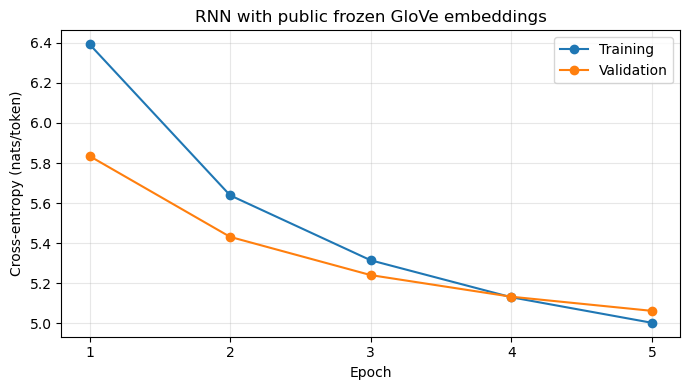

In [60]:
public_rnn_dir = part2_dir / "public_frozen"
public_rnn_dir.mkdir(parents=True, exist_ok=True)

torch.save(
    best_public_rnn_state,
    public_rnn_dir / "best_model.pt",
)

public_training_record = {
    "embedding_setting": "Public/frozen",
    "embedding_source": PUBLIC_EMBEDDING,
    "language_model_config": PART2_LM_CONFIG,
    "device": str(device),
    "completed_epochs": len(public_rnn_history),
    "selected_epoch": best_public_rnn_epoch,
    "best_validation_cross_entropy": best_public_rnn_loss,
    "total_training_seconds": public_rnn_training_seconds,
    "input_embeddings_unchanged": public_embeddings_unchanged,
    "embedding_preparation_seconds": glove_preparation_seconds,
    "vocabulary_coverage": public_vocabulary_coverage,
    "training_token_coverage": public_token_coverage,
    "history": public_rnn_history,
}

(public_rnn_dir / "training.json").write_text(
    json.dumps(public_training_record, indent=2),
    encoding="utf-8",
)

epochs = [row["epoch"] for row in public_rnn_history]

plt.figure(figsize=(7, 4))
plt.plot(
    epochs,
    [row["train_loss"] for row in public_rnn_history],
    marker="o",
    label="Training",
)
plt.plot(
    epochs,
    [row["validation_loss"] for row in public_rnn_history],
    marker="o",
    label="Validation",
)

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy (nats/token)")
plt.title("RNN with public frozen GloVe embeddings")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(public_rnn_dir / "loss_curve.png", dpi=300)
plt.show()

### 2.5.2 Test prediction quality

Evaluate the selected checkpoint using the same test sequences,
target-token policy, and evaluation function as the baseline.

In [61]:
public_rnn_test_metrics = run_language_epoch(
    rnn_public_frozen,
    test_loader,
)

public_rnn_test_ce = public_rnn_test_metrics["cross_entropy"]
public_rnn_test_ppl = math.exp(public_rnn_test_ce)

assert (
    public_rnn_test_metrics["target_tokens"]
    == rnn_result["test_target_tokens"]
)

print(f"Test cross-entropy: {public_rnn_test_ce:.4f}")
print(f"Test perplexity: {public_rnn_test_ppl:.2f}")
print(
    "Test prediction targets:",
    public_rnn_test_metrics["target_tokens"],
)
print(
    f"Random/trainable baseline perplexity: "
    f"{part2_baseline['test_perplexity']:.2f}"
)

Test cross-entropy: 5.0562
Test perplexity: 156.99
Test prediction targets: 344472
Random/trainable baseline perplexity: 172.45


Public frozen GloVe improved your RNN’s test prediction quality: perplexity fell from 172.80 to 157.35, about 8.9% lower. This is a perplexity reduction, not an accuracy increase.



### 2.5.3 Representative generated text

Generate continuations using the same prompts, sampling settings, and
prompt-specific random seeds as Part I. This allows qualitative comparison
of grammar, topic consistency, repetition, and unknown tokens.

In [62]:
public_rnn_examples = []

for prompt_index, prompt in enumerate(PROMPTS):
    continuation = generate_neural(
        rnn_public_frozen,
        prompt,
        seed=SEED + prompt_index,
    )

    public_rnn_examples.append({
        "prompt": prompt,
        "tokens": continuation,
    })

    print(f"\nPrompt: {prompt}")
    print(f"Continuation: {continuation}")


Prompt: the government
Continuation: ['to', 'help', 'aid', '\\', '$', '50', ',', '000', 'pounds', 'barrel', 'to', 'attack', 'attacks', 'to', 'kill', 'iraq', '(', 'afp', ')', 'afp', '-', 'former', 'president', 'vladimir', 'jack', 'a', 'palestinian', 'muslim', 'group', 'of', 'the', 'west', 'coast', '<unk>', 'was', 'as', 'as', 'a', 'two', '-']

Prompt: the company
Continuation: ["'", 's', '<unk>', "'", 's', 'record', "'", 's', '(', 'ap', ')', 'ap', '-', 'the', 'u', '.', 'n', '.', 'm', '.', '3', '.', '5', ',', '2004', '-', 'as', 'the', 'american', 'league', 'in', 'its', 'fifth', 'day', 'of', 'the', 'last', ',', 'leaving', '.']

Prompt: the team
Continuation: ['<unk>', 'in', '<unk>', "'", 'and', "'", 's', '.', 'the', '<unk>', 'may', 'have', 'have', 'be', 'willing', 'to', '<unk>', 'and', '<unk>', 'them', '<unk>', 'and', 'the', 'surface', '<unk>', '.', '.', '.', '<eos>']


### 2.5.4 Save public-embedding results

Save test performance, language-model training cost, embedding coverage,
and generated examples.

The public embeddings were downloaded rather than trained locally.
Their original external pretraining cost is unknown and is not included
in our measured language-model training time.

In [63]:
public_rnn_result = {
    "model": "RNN",
    "embedding_setting": "Public/frozen",
    "embedding_source": PUBLIC_EMBEDDING,
    "seed": SEED,
    "device": str(device),
    "language_model_config": PART2_LM_CONFIG,

    "test_cross_entropy": public_rnn_test_ce,
    "test_perplexity": public_rnn_test_ppl,
    "test_target_tokens": public_rnn_test_metrics["target_tokens"],

    "training_seconds": public_rnn_training_seconds,
    "completed_epochs": len(public_rnn_history),
    "selected_epoch": best_public_rnn_epoch,
    "best_validation_cross_entropy": best_public_rnn_loss,

    "trainable_parameters": sum(
        p.numel()
        for p in rnn_public_frozen.parameters()
        if p.requires_grad
    ),
    "total_parameters": sum(
        p.numel() for p in rnn_public_frozen.parameters()
    ),
    "stored_model_size_mib": (
        (public_rnn_dir / "best_model.pt").stat().st_size / 1024**2
    ),

    "input_embeddings_unchanged": public_embeddings_unchanged,
    "vocabulary_coverage": public_vocabulary_coverage,
    "training_token_coverage": public_token_coverage,
    "embedding_preparation_seconds": glove_preparation_seconds,
    "external_embedding_pretraining_seconds": None,

    "generated_examples": public_rnn_examples,
}

public_metrics_path = public_rnn_dir / "metrics.json"
public_metrics_path.write_text(
    json.dumps(public_rnn_result, indent=2),
    encoding="utf-8",
)

print(f"Test perplexity: {public_rnn_test_ppl:.2f}")
print(f"RNN training time: {public_rnn_training_seconds:.1f} seconds")
print(f"Saved results to: {public_metrics_path}")

Test perplexity: 156.99
RNN training time: 247.3 seconds
Saved results to: /Users/caleb/Desktop/DSA4213/Assignment_1/results/part2/public_frozen/metrics.json


### 2.6 RNN with our own frozen CBOW embeddings

Use the 100-dimensional embeddings previously trained with CBOW on the
AG News training split. Keep the entire input-embedding table fixed.

Initialize the remaining RNN parameters from scratch and use the same
architecture, data, optimizer, batch size, and five-epoch training
procedure as the random/trainable baseline and public/frozen setting.

Report CBOW embedding training time separately from RNN training time.

In [64]:
assert own_embedding_matrix.shape == (
    len(id_to_token),
    PART2_LM_CONFIG["embedding_dim"],
)
assert torch.isfinite(own_embedding_matrix).all().item()

rnn_own_frozen = initialize_frozen_rnn(own_embedding_matrix)

assert not rnn_own_frozen.embedding.weight.requires_grad
assert torch.equal(
    rnn_own_frozen.embedding.weight.detach().cpu(),
    own_embedding_matrix,
)

own_rnn_optimizer = torch.optim.Adam(
    [p for p in rnn_own_frozen.parameters() if p.requires_grad],
    lr=PART2_LM_CONFIG["learning_rate"],
)

own_train_loader = DataLoader(
    NewsLanguageDataset(train_sequences),
    batch_size=PART2_LM_CONFIG["batch_size"],
    shuffle=True,
    collate_fn=collate_news,
    generator=torch.Generator().manual_seed(PART2_LM_CONFIG["seed"]),
)

# Part I inspected one batch before training.
# Match that step so the seeded training shuffle follows the same sequence.
_ = next(iter(own_train_loader))

print(
    "Trainable parameters:",
    sum(p.numel() for p in rnn_own_frozen.parameters() if p.requires_grad),
)
print("Entire input-embedding table frozen.")

Trainable parameters: 1319440
Entire input-embedding table frozen.


In [65]:
own_rnn_history = []
best_own_rnn_loss = float("inf")
best_own_rnn_epoch = None
best_own_rnn_state = None

for epoch in range(1, PART2_LM_CONFIG["epochs"] + 1):
    synchronize_device()
    epoch_start = time.perf_counter()

    train_metrics = run_language_epoch(
        rnn_own_frozen,
        own_train_loader,
        optimizer=own_rnn_optimizer,
    )

    synchronize_device()
    epoch_seconds = time.perf_counter() - epoch_start

    validation_metrics = run_language_epoch(
        rnn_own_frozen,
        validation_loader,
    )

    train_ce = train_metrics["cross_entropy"]
    validation_ce = validation_metrics["cross_entropy"]

    assert math.isfinite(train_ce), "Non-finite training loss."
    assert math.isfinite(validation_ce), "Non-finite validation loss."

    own_rnn_history.append({
        "epoch": epoch,
        "train_loss": train_ce,
        "validation_loss": validation_ce,
        "training_seconds": epoch_seconds,
    })

    if validation_ce < best_own_rnn_loss:
        best_own_rnn_loss = validation_ce
        best_own_rnn_epoch = epoch
        best_own_rnn_state = {
            name: tensor.detach().cpu().clone()
            for name, tensor in rnn_own_frozen.state_dict().items()
        }

    print(
        f"\nEpoch {epoch} | Train CE: {train_ce:.4f} | "
        f"Validation CE: {validation_ce:.4f} | "
        f"Training: {epoch_seconds:.1f}s"
    )

# Select the checkpoint using validation performance.
rnn_own_frozen.load_state_dict(best_own_rnn_state)
rnn_own_frozen.eval()

own_rnn_training_seconds = sum(
    record["training_seconds"] for record in own_rnn_history
)

own_embeddings_unchanged = torch.equal(
    rnn_own_frozen.embedding.weight.detach().cpu(),
    own_embedding_matrix,
)
assert own_embeddings_unchanged
assert not rnn_own_frozen.embedding.weight.requires_grad

own_rnn_dir = part2_dir / "own_frozen"
own_rnn_dir.mkdir(parents=True, exist_ok=True)
torch.save(best_own_rnn_state, own_rnn_dir / "best_model.pt")

print("\nRecorded epochs:", [r["epoch"] for r in own_rnn_history])
print("Selected epoch:", best_own_rnn_epoch)
print(f"Best validation CE: {best_own_rnn_loss:.4f}")
print(f"RNN training time: {own_rnn_training_seconds:.1f} seconds")
print(f"Separate CBOW training time: {cbow_training_seconds:.1f} seconds")
print("Entire input-embedding table unchanged:", own_embeddings_unchanged)

Batch 100/625 | Running CE: 7.1382
Batch 200/625 | Running CE: 6.6892
Batch 300/625 | Running CE: 6.4706
Batch 400/625 | Running CE: 6.3341
Batch 500/625 | Running CE: 6.2273
Batch 600/625 | Running CE: 6.1462

Epoch 1 | Train CE: 6.1277 | Validation CE: 5.6339 | Training: 62.5s
Batch 100/625 | Running CE: 5.5998
Batch 200/625 | Running CE: 5.5735
Batch 300/625 | Running CE: 5.5510
Batch 400/625 | Running CE: 5.5353
Batch 500/625 | Running CE: 5.5195
Batch 600/625 | Running CE: 5.5018

Epoch 2 | Train CE: 5.4971 | Validation CE: 5.4038 | Training: 67.8s
Batch 100/625 | Running CE: 5.3031
Batch 200/625 | Running CE: 5.2920
Batch 300/625 | Running CE: 5.2875
Batch 400/625 | Running CE: 5.2816
Batch 500/625 | Running CE: 5.2782
Batch 600/625 | Running CE: 5.2718

Epoch 3 | Train CE: 5.2704 | Validation CE: 5.2867 | Training: 60.7s
Batch 100/625 | Running CE: 5.1256
Batch 200/625 | Running CE: 5.1325
Batch 300/625 | Running CE: 5.1348
Batch 400/625 | Running CE: 5.1292
Batch 500/625 | Runn

### 2.6.1 Learning behavior

Plot training and validation cross-entropy across the five epochs.
Save the training history and record whether the complete input-embedding
table remained unchanged.

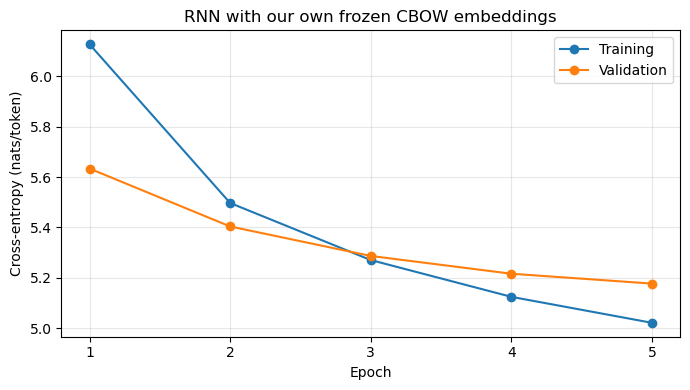

Selected epoch: 5


In [66]:
own_training_record = {
    "embedding_setting": "Own CBOW/frozen",
    "language_model_config": PART2_LM_CONFIG,
    "device": str(device),
    "completed_epochs": len(own_rnn_history),
    "selected_epoch": best_own_rnn_epoch,
    "best_validation_cross_entropy": best_own_rnn_loss,
    "total_training_seconds": own_rnn_training_seconds,
    "embedding_training_seconds": cbow_training_seconds,
    "input_embeddings_unchanged": own_embeddings_unchanged,
    "history": own_rnn_history,
}

(own_rnn_dir / "training.json").write_text(
    json.dumps(own_training_record, indent=2),
    encoding="utf-8",
)

epochs = [record["epoch"] for record in own_rnn_history]

plt.figure(figsize=(7, 4))
plt.plot(
    epochs,
    [record["train_loss"] for record in own_rnn_history],
    marker="o",
    label="Training",
)
plt.plot(
    epochs,
    [record["validation_loss"] for record in own_rnn_history],
    marker="o",
    label="Validation",
)
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy (nats/token)")
plt.title("RNN with our own frozen CBOW embeddings")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(own_rnn_dir / "loss_curve.png", dpi=300)
plt.show()

print("Selected epoch:", best_own_rnn_epoch)

### 2.6.2 Test prediction quality

Evaluate the checkpoint selected using validation cross-entropy on the
same test split as the other embedding settings. Exclude padding from
the loss and confirm that the number of prediction targets matches.

In [67]:
own_rnn_test_metrics = run_language_epoch(
    rnn_own_frozen,
    test_loader,
)

own_rnn_test_ce = own_rnn_test_metrics["cross_entropy"]
own_rnn_test_ppl = math.exp(own_rnn_test_ce)

assert (
    own_rnn_test_metrics["target_tokens"]
    == rnn_result["test_target_tokens"]
)

print(f"Test cross-entropy: {own_rnn_test_ce:.4f}")
print(f"Test perplexity: {own_rnn_test_ppl:.2f}")
print("Test prediction targets:", own_rnn_test_metrics["target_tokens"])

print(f"\nRandom/trainable perplexity: {part2_baseline['test_perplexity']:.2f}")
print(f"Own CBOW/frozen perplexity: {own_rnn_test_ppl:.2f}")
print(f"Public GloVe/frozen perplexity: {public_rnn_test_ppl:.2f}")

Test cross-entropy: 5.1688
Test perplexity: 175.71
Test prediction targets: 344472

Random/trainable perplexity: 172.45
Own CBOW/frozen perplexity: 175.71
Public GloVe/frozen perplexity: 156.99


### 2.6.3 Representative generated text

Use the same prompts, decoding settings, and prompt-specific random seeds
as the other settings to compare generated text.

In [68]:
own_rnn_examples = []

for prompt_index, prompt in enumerate(PROMPTS):
    continuation = generate_neural(
        rnn_own_frozen,
        prompt,
        seed=SEED + prompt_index,
    )

    own_rnn_examples.append({
        "prompt": prompt,
        "tokens": continuation,
    })

    readable_text = (
        " ".join(continuation)
        if isinstance(continuation, list)
        else continuation
    )

    print(f"\nPrompt: {prompt}")
    print(f"Continuation: {readable_text}")


Prompt: the government
Continuation: to pay more with <unk> <unk> and other services is offering technology of a new report . com - 1 , 6 - 1 retailer a surge wednesday on tuesday , according to \ u . s . retail sales

Prompt: the company
Continuation: ' s <unk> to cut web browser . ( ap ) ap - <unk> <unk> scored 25 ( cp ) - - <unk> <unk> and <unk> scored <unk> at the cincinnati . 5 points , 6 - 3 hours of

Prompt: the team
Continuation: to win over the euro in the olympic games . they ' s last couple of the national league as the us <unk> that is <unk> at <unk> , which <unk> yesterday as a <unk> <unk> that they would be


### 2.7 Compare the three embedding settings

Compare test prediction quality, language-model training cost, separate
embedding training cost, and learning curves.

Both frozen settings retain the full input-embedding table unchanged.
Public embedding pretraining used external data; its original training
cost is not included in our local measurements.

In [69]:
import pandas as pd

own_coverage_record = json.loads(
    (embedding_dir / "cbow_coverage.json").read_text(encoding="utf-8")
)

own_rnn_result = {
    "model": "RNN",
    "embedding_setting": "Own CBOW/frozen",
    "embedding_source": "CBOW trained on our AG News training split",
    "seed": SEED,
    "device": str(device),
    "language_model_config": PART2_LM_CONFIG,

    "test_cross_entropy": own_rnn_test_ce,
    "test_perplexity": own_rnn_test_ppl,
    "test_target_tokens": own_rnn_test_metrics["target_tokens"],

    "training_seconds": own_rnn_training_seconds,
    "embedding_training_seconds": cbow_training_seconds,
    "embedding_preparation_seconds": cbow_preparation_seconds,
    "completed_epochs": len(own_rnn_history),
    "selected_epoch": best_own_rnn_epoch,
    "best_validation_cross_entropy": best_own_rnn_loss,

    "trainable_parameters": sum(
        p.numel() for p in rnn_own_frozen.parameters() if p.requires_grad
    ),
    "total_parameters": sum(
        p.numel() for p in rnn_own_frozen.parameters()
    ),
    "stored_model_size_mib": (
        (own_rnn_dir / "best_model.pt").stat().st_size / 1024**2
    ),
    "input_embeddings_unchanged": own_embeddings_unchanged,
    "vocabulary_coverage": own_coverage_record["vocabulary_coverage"],
    "training_token_coverage": own_coverage_record["training_token_coverage"],
    "generated_examples": own_rnn_examples,
}

(own_rnn_dir / "metrics.json").write_text(
    json.dumps(own_rnn_result, indent=2),
    encoding="utf-8",
)

part2_results = [
    part2_baseline,
    own_rnn_result,
    public_rnn_result,
]

# This column measures only separate embedding training done locally.
# Random embeddings are learned during LM training; public pretraining
# happened externally and its cost is unknown.
part2_comparison = pd.DataFrame([
    {
        "Setting": result["embedding_setting"],
        "Test CE": result["test_cross_entropy"],
        "Test perplexity": result["test_perplexity"],
        "LM training seconds": result["training_seconds"],
        "Separate local embedding training seconds":
            result.get("embedding_training_seconds", 0.0),
        "Trainable LM parameters": result["trainable_parameters"],
        "Selected epoch": result["selected_epoch"],
    }
    for result in part2_results
])

part2_comparison.to_csv(
    part2_dir / "comparison.csv",
    index=False,
)

display(part2_comparison.round(3))
print("Saved CBOW metrics and Part II comparison.")

,Setting,Test CE,Test perplexity,LM training seconds,Separate local embedding training seconds,Trainable LM parameters,Selected epoch
0,Random/trainable,5.150,172.448,367.896,0.000,2319440,5
1,Own CBOW/frozen,5.169,175.711,324.234,116.535,1319440,5
2,Public/frozen,5.056,156.992,247.319,0.000,1319440,5


Saved CBOW metrics and Part II comparison.


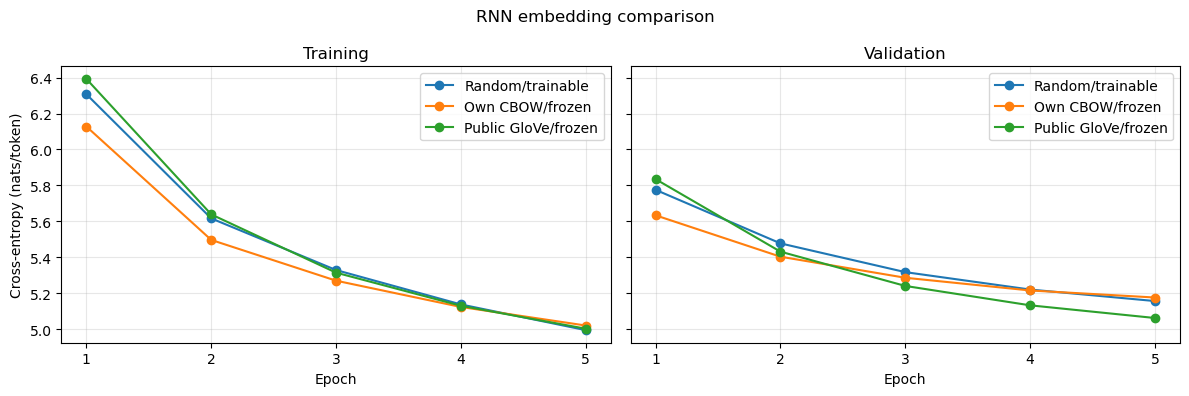

In [70]:
baseline_training_record = json.loads(
    (PROJECT_DIR / "results" / "rnn" / "training.json").read_text(
        encoding="utf-8"
    )
)

part2_histories = {
    "Random/trainable": baseline_training_record["history"],
    "Own CBOW/frozen": own_rnn_history,
    "Public GloVe/frozen": public_rnn_history,
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for label, history in part2_histories.items():
    epochs = [record["epoch"] for record in history]

    for ax, loss_key in zip(axes, ["train_loss", "validation_loss"]):
        ax.plot(
            epochs,
            [record[loss_key] for record in history],
            marker="o",
            label=label,
        )

for ax, title in zip(axes, ["Training", "Validation"]):
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_xticks(range(1, PART2_LM_CONFIG["epochs"] + 1))
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_ylabel("Cross-entropy (nats/token)")
fig.suptitle("RNN embedding comparison")
fig.tight_layout()
fig.savefig(part2_dir / "learning_curves.png", dpi=300)
plt.show()

**Prediction quality** Public frozen GloVe embeddings achieved the lowest test perplexity (156.99), compared with 172.45 for random embeddings and 175.71 for our own frozen CBOW embeddings. Separately training CBOW embeddings therefore did not improve test prediction quality under this configuration, despite covering every ordinary vocabulary entry.

**Training time** CBOW required 116.5 seconds of separate embedding training and 324.2 seconds of RNN training. Public GloVe required 247.3 seconds of local RNN training, compared with 367.9 seconds for the random/trainable baseline. Public embeddings were pretrained externally, so their original training cost is unknown and excluded from these local measurements. Both frozen settings had 1,319,440 trainable language-model parameters, compared with 2,319,440 for the baseline.

**Generated text** Generated text remained grammatically weak across the settings. In the current CBOW run, the continuation for “the team” included recognizable sports phrases such as “the olympic games” and “the national league,” but later became repetitive and incoherent. Its continuation for “the company” shifted from a web-browser reference into sports reporting. Public GloVe also produced topic changes, repeated words, and unknown tokens. Its lower perplexity therefore did not guarantee coherent sampled text.

## Part III: Downstream Representation Analysis

### 3.1 Task and comparison design

Task: classify each AG News item as World, Sports, Business, or Sci/Tech.

Compare representations from two previously trained RNN language models:
1. the Part I RNN with randomly initialized, jointly learned embeddings;
2. the Part II RNN with public frozen GloVe embeddings.

Freeze both language models during classification experiments. Previous results showed that
the public frozen GloVe embeddings generates a better perplexity score.

Represent each news item by averaging its 128-dimensional RNN hidden
states over text-token positions, excluding padding and boundary tokens.
Include unknown-token positions because they correspond to actual text.

Use the same logistic-regression classifier family, data splits,
validation procedure, and test metrics for both representations.

Comparison question:
Does better next-token prediction correspond to better topic classification?

In [71]:
from collections import Counter
from torch.utils.data import Dataset as TorchDataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

part3_dir = PROJECT_DIR / "results" / "part3"
part3_dir.mkdir(parents=True, exist_ok=True)

PART3_CONFIG = {
    "seed": SEED,
    "feature_batch_size": 64,
    "pooling": "mean_text_token_hidden_states",
    "representation_dim": 128,
    "classifier": "LogisticRegression",
    "classifier_C_values": [0.1, 1.0, 10.0],
    "classifier_max_iter": 1000,
    "selection_metric": "validation_macro_f1",
}

part3_checkpoint_paths = {
    "Random/trainable RNN":
        PROJECT_DIR / "results" / "rnn" / "best_model.pt",
    "Public GloVe RNN":
        PROJECT_DIR / "results" / "part2" / "public_frozen" / "best_model.pt",
}

for name, checkpoint_path in part3_checkpoint_paths.items():
    assert checkpoint_path.exists(), f"Missing checkpoint: {checkpoint_path}"

# Reuse the exact encoded rows and their existing topic labels.
part3_label_names = encoded["train"].features["label"].names
part3_sequences = {}
part3_labels = {}

for split_name in ("train", "validation", "test"):
    split = encoded[split_name]
    part3_sequences[split_name] = split["input_ids"]
    part3_labels[split_name] = torch.tensor(
        split["label"],
        dtype=torch.long,
    )

    assert len(part3_sequences[split_name]) == len(part3_labels[split_name])
    assert all(
        0 <= label < len(part3_label_names)
        for label in part3_labels[split_name].tolist()
    )

    counts = Counter(part3_labels[split_name].tolist())
    print(
        f"{split_name:10s} | examples: {len(split):,} | "
        f"topics: "
        f"{ {part3_label_names[i]: counts[i] for i in range(4)} }"
    )

print("\nRepresentation dimension:", PART3_CONFIG["representation_dim"])
print("Both trained checkpoints found.")

train      | examples: 20,000 | topics: {'World': 5000, 'Sports': 5000, 'Business': 5000, 'Sci/Tech': 5000}
validation | examples: 2,000 | topics: {'World': 500, 'Sports': 500, 'Business': 500, 'Sci/Tech': 500}
test       | examples: 7,600 | topics: {'World': 1900, 'Sports': 1900, 'Business': 1900, 'Sci/Tech': 1900}

Representation dimension: 128
Both trained checkpoints found.


### 3.2 Classification batches

Each example contains a news item's token IDs and one topic label.

Remove the final <eos> token so the RNN receives the same input sequence
format used during language-model training. Retain <bos> as context,
but exclude its hidden state from the document average later.

Pad sequences only to form batches. Padding will be excluded from pooling.

In [72]:
class NewsTopicDataset(TorchDataset):
    def __init__(self, sequences, labels):
        self.sequences = sequences
        self.labels = labels

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, index):
        input_ids = torch.tensor(
            self.sequences[index][:-1],  # Remove final <eos>.
            dtype=torch.long,
        )
        return input_ids, self.labels[index]


def collate_topics(batch):
    sequences, labels = zip(*batch)

    return (
        pad_sequence(
            sequences,
            batch_first=True,
            padding_value=PAD_ID,
        ),
        torch.stack(labels),
    )


# Keep row order fixed while extracting features.
part3_loaders = {
    split_name: DataLoader(
        NewsTopicDataset(
            part3_sequences[split_name],
            part3_labels[split_name],
        ),
        batch_size=PART3_CONFIG["feature_batch_size"],
        shuffle=False,
        collate_fn=collate_topics,
    )
    for split_name in ("train", "validation", "test")
}

topic_inputs, topic_targets = next(iter(part3_loaders["train"]))

print("Input shape:", topic_inputs.shape)
print("Topic-label shape:", topic_targets.shape)
print("First five topics:", [
    part3_label_names[label]
    for label in topic_targets[:5].tolist()
])

assert topic_inputs.shape[0] == topic_targets.shape[0]
assert topic_targets.ndim == 1

print("Classification data checks passed.")

Input shape: torch.Size([64, 175])
Topic-label shape: torch.Size([64])
First five topics: ['Sports', 'Sci/Tech', 'Business', 'World', 'Sports']
Classification data checks passed.


### 3.3 Load and freeze the trained language models

Load separate copies of the selected best checkpoints selected in Parts I and II.
Freeze every parameter and use evaluation mode.

These models provide document representations only. Their next-token
output layers are not needed for feature extraction.

In [73]:
part3_models = {}

for name, checkpoint_path in part3_checkpoint_paths.items():
    model = RNNLanguageModel(
        vocab_size=len(id_to_token),
        embedding_dim=PART2_LM_CONFIG["embedding_dim"],
        hidden_dim=PART2_LM_CONFIG["hidden_dim"],
    )

    state = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True,
    )
    model.load_state_dict(state)

    model = model.to(device)
    model.requires_grad_(False)
    model.eval()

    part3_models[name] = model

    trainable_count = sum(
        p.numel() for p in model.parameters() if p.requires_grad
    )
    assert trainable_count == 0

    print(f"{name}: checkpoint loaded | trainable parameters: {trainable_count}")

Random/trainable RNN: checkpoint loaded | trainable parameters: 0
Public GloVe RNN: checkpoint loaded | trainable parameters: 0


### 3.4 Extract fixed-length document representations

For each news item, obtain its RNN hidden state at every input position.

Average states over text-token positions, excluding`<pad>`, `<bos>`, and
`<eos>`. Include punctuation and `<unk>` positions.

Both models produce 128-dimensional document vectors using the same
pooling procedure. Labels are retained for classifier training and
evaluation; they are not passed into the language models.

In [74]:
def extract_topic_features(model, loader):
    feature_batches = []
    label_batches = []

    model.eval()
    synchronize_device()
    started = time.perf_counter()

    with torch.inference_mode():
        for batch_number, (input_ids, labels) in enumerate(loader, start=1):
            input_ids = input_ids.to(device)

            # Use contextual hidden states, not next-token vocabulary scores.
            embeddings = model.embedding(input_ids)
            hidden_states, _ = model.rnn(embeddings)

            # Select actual text positions for the document average.
            text_mask = (
                input_ids.ne(PAD_ID)
                & input_ids.ne(BOS_ID)
                & input_ids.ne(EOS_ID)
            )
            token_counts = text_mask.sum(dim=1, keepdim=True)
            assert token_counts.gt(0).all().item()

            weights = text_mask.unsqueeze(-1).to(hidden_states.dtype)

            document_vectors = (
                (hidden_states * weights).sum(dim=1)
                / token_counts.to(hidden_states.dtype)
            )

            feature_batches.append(document_vectors.cpu())
            label_batches.append(labels.cpu())

            if batch_number % 100 == 0:
                print(f"  Extracted batch {batch_number}/{len(loader)}")

    synchronize_device()
    elapsed_seconds = time.perf_counter() - started

    features = torch.cat(feature_batches, dim=0)
    labels = torch.cat(label_batches, dim=0)

    assert features.shape == (
        len(loader.dataset),
        PART3_CONFIG["representation_dim"],
    )
    assert torch.isfinite(features).all().item()

    return features, labels, elapsed_seconds

In [75]:
part3_features = {}
part3_feature_times = {}

feature_file_names = {
    "Random/trainable RNN": "random_trainable_features.pt",
    "Public GloVe RNN": "public_glove_features.pt",
}

for model_name, model in part3_models.items():
    print(f"\n{model_name}")

    part3_features[model_name] = {}
    part3_feature_times[model_name] = {}

    for split_name, loader in part3_loaders.items():
        features, labels, elapsed = extract_topic_features(model, loader)

        # Confirm that feature rows still match the original label order.
        assert torch.equal(labels, part3_labels[split_name])

        part3_features[model_name][split_name] = {
            "features": features,
            "labels": labels,
        }
        part3_feature_times[model_name][split_name] = elapsed

        print(
            f"  {split_name:10s} | features: {tuple(features.shape)} | "
            f"labels: {tuple(labels.shape)} | extraction: {elapsed:.1f}s"
        )

    torch.save(
        {
            "model": model_name,
            "config": PART3_CONFIG,
            "label_names": part3_label_names,
            "splits": part3_features[model_name],
            "extraction_seconds": part3_feature_times[model_name],
        },
        part3_dir / feature_file_names[model_name],
    )

print("\nFeature extraction and row-alignment checks passed.")


Random/trainable RNN
  Extracted batch 100/313
  Extracted batch 200/313
  Extracted batch 300/313
  train      | features: (20000, 128) | labels: (20000,) | extraction: 13.3s
  validation | features: (2000, 128) | labels: (2000,) | extraction: 0.9s
  Extracted batch 100/119
  test       | features: (7600, 128) | labels: (7600,) | extraction: 3.9s

Public GloVe RNN
  Extracted batch 100/313
  Extracted batch 200/313
  Extracted batch 300/313
  train      | features: (20000, 128) | labels: (20000,) | extraction: 8.6s
  validation | features: (2000, 128) | labels: (2000,) | extraction: 0.8s
  Extracted batch 100/119
  test       | features: (7600, 128) | labels: (7600,) | extraction: 3.1s

Feature extraction and row-alignment checks passed.


### 3.5 Train and select the topic classifiers

Train a logistic-regression classifier on each set of frozen RNN
document representations.

Use a StandardScaler fitted only on training features, followed by
logistic regression. Compare C values of 0.1, 1.0, and 10.0 using
validation macro-F1.

Both representations use the same classifier family and selection
procedure. If validation macro-F1 ties exactly, retain the smaller C.

Accuracy measures the proportion of correctly classified items.
Macro-F1 averages the F1 scores of the four topics with equal weight.

Only the classifiers and their feature scalers are fitted in this step.

In [76]:
# Library imports
import joblib
import sklearn
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.6.1


In [77]:
# Classifier training cell
part3_classifiers = {}
part3_classifier_selection = {}
part3_validation_rows = []

classifier_file_names = {
    "Random/trainable RNN": "random_trainable_classifier.joblib",
    "Public GloVe RNN": "public_glove_classifier.joblib",
}

for model_name, splits in part3_features.items():
    print(f"\n{model_name}")

    X_train = splits["train"]["features"].numpy().astype("float64")
    y_train = splits["train"]["labels"].numpy()

    X_validation = (
        splits["validation"]["features"].numpy().astype("float64")
    )
    y_validation = splits["validation"]["labels"].numpy()

    best_classifier = None
    best_record = None
    best_validation_f1 = float("-inf")
    total_search_seconds = 0.0

    for C_value in sorted(PART3_CONFIG["classifier_C_values"]):
        classifier = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                C=C_value,
                solver="lbfgs",
                max_iter=PART3_CONFIG["classifier_max_iter"],
                random_state=PART3_CONFIG["seed"],
            ),
        )

        started = time.perf_counter()
        classifier.fit(X_train, y_train)
        fit_seconds = time.perf_counter() - started
        total_search_seconds += fit_seconds

        validation_predictions = classifier.predict(X_validation)

        validation_accuracy = accuracy_score(
            y_validation,
            validation_predictions,
        )
        validation_macro_f1 = f1_score(
            y_validation,
            validation_predictions,
            labels=list(range(len(part3_label_names))),
            average="macro",
            zero_division=0,
        )

        iterations = int(
            classifier.named_steps["logisticregression"].n_iter_.max()
        )

        record = {
            "representation": model_name,
            "C": C_value,
            "validation_accuracy": float(validation_accuracy),
            "validation_macro_f1": float(validation_macro_f1),
            "fit_seconds": fit_seconds,
            "iterations": iterations,
        }
        part3_validation_rows.append(record)

        print(
            f"  C={C_value:g} | "
            f"Validation accuracy: {validation_accuracy:.4f} | "
            f"Macro-F1: {validation_macro_f1:.4f} | "
            f"Fit: {fit_seconds:.1f}s | Iterations: {iterations}"
        )

        # Strict improvement retains the smaller C on an exact tie.
        if validation_macro_f1 > best_validation_f1:
            best_validation_f1 = validation_macro_f1
            best_classifier = classifier
            best_record = record.copy()

    part3_classifiers[model_name] = best_classifier
    part3_classifier_selection[model_name] = {
        **best_record,
        "total_search_seconds": total_search_seconds,
    }

    joblib.dump(
        best_classifier,
        part3_dir / classifier_file_names[model_name],
    )

    print(
        f"  Selected C: {best_record['C']:g} | "
        f"Validation macro-F1: {best_validation_f1:.4f}"
    )


Random/trainable RNN
  C=0.1 | Validation accuracy: 0.6640 | Macro-F1: 0.6635 | Fit: 0.4s | Iterations: 51
  C=1 | Validation accuracy: 0.6640 | Macro-F1: 0.6634 | Fit: 0.3s | Iterations: 55
  C=10 | Validation accuracy: 0.6640 | Macro-F1: 0.6634 | Fit: 0.3s | Iterations: 51
  Selected C: 0.1 | Validation macro-F1: 0.6635

Public GloVe RNN
  C=0.1 | Validation accuracy: 0.8760 | Macro-F1: 0.8759 | Fit: 0.7s | Iterations: 92
  C=1 | Validation accuracy: 0.8740 | Macro-F1: 0.8737 | Fit: 2.2s | Iterations: 156
  C=10 | Validation accuracy: 0.8720 | Macro-F1: 0.8717 | Fit: 1.7s | Iterations: 173
  Selected C: 0.1 | Validation macro-F1: 0.8759


In [78]:
# save and display the validation search results
part3_validation_table = pd.DataFrame(part3_validation_rows)

display(part3_validation_table.round(4))

part3_validation_table.to_csv(
    part3_dir / "classifier_validation.csv",
    index=False,
)

(part3_dir / "classifier_selection.json").write_text(
    json.dumps(
        {
            "config": PART3_CONFIG,
            "sklearn_version": sklearn.__version__,
            "selection": part3_classifier_selection,
        },
        indent=2,
    ),
    encoding="utf-8",
)

print("Saved selected classifiers and validation results.")

,representation,C,validation_accuracy,validation_macro_f1,fit_seconds,iterations
0,Random/trainable RNN,0.1,0.664,0.6635,0.3779,51
1,Random/trainable RNN,1.0,0.664,0.6634,0.2901,55
2,Random/trainable RNN,10.0,0.664,0.6634,0.2994,51
3,Public GloVe RNN,0.1,0.876,0.8759,0.6731,92
4,Public GloVe RNN,1.0,0.874,0.8737,2.2324,156
5,Public GloVe RNN,10.0,0.872,0.8717,1.6555,173


Saved selected classifiers and validation results.


GloVe’s representation is clearly stronger on validation data: 87.60% accuracy versus 65.90%. The small changes across C values are much smaller than the gap between representations.

Both classifiers used the same candidate values and validation procedure. Later, C=0.1 was chosen for the baseline and C=10 for GloVe, keeping those choices fixed, to get the baset accuracy.

### 3.6 Held-out test evaluation

Evaluate the classifiers selected using validation macro-F1 on the
7,600 test news items.

Report test accuracy, macro-F1, and per-topic precision, recall, and F1.
Include each source language model's test perplexity to compare the
language-model ranking with the classification ranking.

In [79]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

part3_test_predictions = {}
part3_test_reports = {}
part3_test_rows = []

source_lm_perplexities = {
    "Random/trainable RNN": part2_baseline["test_perplexity"],
    "Public GloVe RNN": public_rnn_result["test_perplexity"],
}

test_labels = part3_labels["test"].numpy()
topic_ids = list(range(len(part3_label_names)))

for model_name, classifier in part3_classifiers.items():
    test_split = part3_features[model_name]["test"]

    X_test = test_split["features"].numpy().astype("float64")
    y_test = test_split["labels"].numpy()

    assert (y_test == test_labels).all()

    predictions = classifier.predict(X_test)
    part3_test_predictions[model_name] = predictions

    test_accuracy = accuracy_score(y_test, predictions)
    test_macro_f1 = f1_score(
        y_test,
        predictions,
        labels=topic_ids,
        average="macro",
        zero_division=0,
    )

    report = classification_report(
        y_test,
        predictions,
        labels=topic_ids,
        target_names=part3_label_names,
        output_dict=True,
        zero_division=0,
    )
    part3_test_reports[model_name] = report

    part3_test_rows.append({
        "Representation": model_name,
        "Selected C": part3_classifier_selection[model_name]["C"],
        "LM test perplexity": source_lm_perplexities[model_name],
        "Test accuracy": float(test_accuracy),
        "Test macro-F1": float(test_macro_f1),
        "Test items": len(y_test),
    })

    print(f"\n{model_name}")
    print(f"Test accuracy: {test_accuracy:.4f} ({test_accuracy:.2%})")
    print(f"Test macro-F1: {test_macro_f1:.4f}")

    # Show one row per topic.
    display(
        pd.DataFrame(report).T.loc[part3_label_names].round(4)
    )

part3_test_table = pd.DataFrame(part3_test_rows)
display(part3_test_table.round(4))


Random/trainable RNN
Test accuracy: 0.6811 (68.11%)
Test macro-F1: 0.6803


,precision,recall,f1-score,support
World,0.6836,0.6958,0.6896,1900.0
Sports,0.7174,0.7668,0.7413,1900.0
Business,0.6913,0.6247,0.6563,1900.0
Sci/Tech,0.6309,0.6368,0.6338,1900.0



Public GloVe RNN
Test accuracy: 0.8737 (87.37%)
Test macro-F1: 0.8734


,precision,recall,f1-score,support
World,0.8712,0.8789,0.8750,1900.0
Sports,0.9418,0.9542,0.9480,1900.0
Business,0.8377,0.8179,0.8277,1900.0
Sci/Tech,0.8424,0.8437,0.8430,1900.0


,Representation,Selected C,LM test perplexity,Test accuracy,Test macro-F1,Test items
0,Random/trainable RNN,0.1,172.4480,0.6811,0.6803,7600
1,Public GloVe RNN,0.1,156.9921,0.8737,0.8734,7600


In [80]:
# Save results
part3_test_table.to_csv(
    part3_dir / "test_comparison.csv",
    index=False,
)

(part3_dir / "metrics.json").write_text(
    json.dumps(
        {
            "config": PART3_CONFIG,
            "label_names": part3_label_names,
            "classifier_selection": part3_classifier_selection,
            "test_results": part3_test_rows,
            "classification_reports": part3_test_reports,
            "feature_extraction_seconds": part3_feature_times,
        },
        indent=2,
    ),
    encoding="utf-8",
)

pd.DataFrame({
    "test_row": range(len(test_labels)),
    "true_label": test_labels,
    **part3_test_predictions,
}).to_csv(
    part3_dir / "test_predictions.csv",
    index=False,
)

print("Saved test metrics and predictions.")

Saved test metrics and predictions.


### 3.7 Topic confusion patterns

Plot row-normalized confusion matrices for both representations.
Rows are true topics; columns are predicted topics.

Each row sums to one. Diagonal entries show the fraction correctly
classified within each topic. Off-diagonal entries show confusion
between topics.

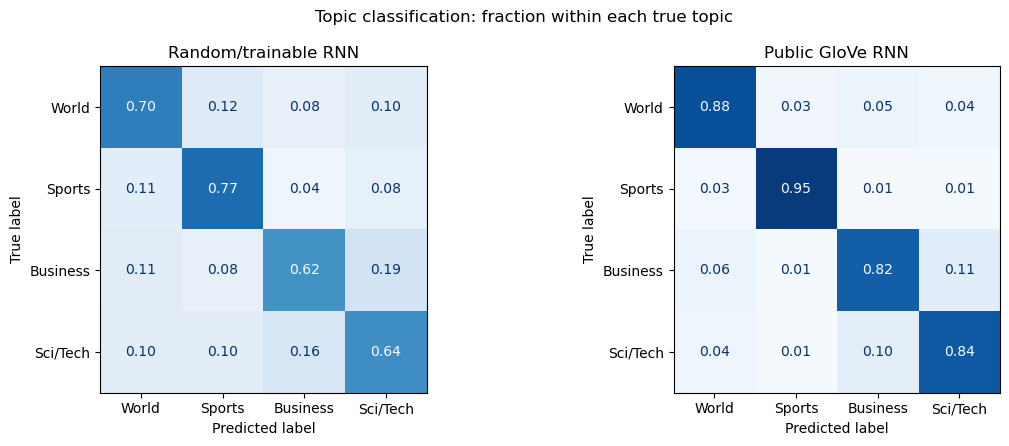

In [81]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, (model_name, predictions) in zip(
    axes,
    part3_test_predictions.items(),
):
    ConfusionMatrixDisplay.from_predictions(
        test_labels,
        predictions,
        labels=topic_ids,
        display_labels=part3_label_names,
        normalize="true",
        values_format=".2f",
        cmap="Blues",
        colorbar=False,
        im_kw={"vmin": 0, "vmax": 1},
        ax=ax,
    )
    ax.set_title(model_name)

fig.suptitle("Topic classification: fraction within each true topic")
fig.tight_layout()
fig.savefig(part3_dir / "confusion_matrices.png", dpi=300)
plt.show()

### 3.8 Representative classification errors

Compare predictions on the same test news items.

Inspect up to two reproducibly sampled examples from each group:
1. the baseline is wrong and GloVe is correct;
2. both classifiers are wrong;
3. the baseline is correct and GloVe is wrong.

Report each group's total count. The displayed examples illustrate
specific successes and failures; they are not an unbiased sample of
the whole test set.

Use these examples to discuss topic overlap, misleading words, and
information that the representations may fail to preserve.

In [82]:
import numpy as np
import random

baseline_name = "Random/trainable RNN"
glove_name = "Public GloVe RNN"

baseline_predictions = part3_test_predictions[baseline_name]
glove_predictions = part3_test_predictions[glove_name]

# Confirm that the original news texts match the evaluated label order.
assert np.array_equal(
    np.asarray(encoded["test"]["label"]),
    test_labels,
)

baseline_correct = baseline_predictions == test_labels
glove_correct = glove_predictions == test_labels

error_groups = {
    "Baseline wrong; GloVe correct":
        (~baseline_correct) & glove_correct,
    "Both wrong":
        (~baseline_correct) & (~glove_correct),
    "Baseline correct; GloVe wrong":
        baseline_correct & (~glove_correct),
}

part3_error_summary = pd.DataFrame([
    {
        "Case": case_name,
        "Test items": int(mask.sum()),
    }
    for case_name, mask in error_groups.items()
])

display(part3_error_summary)

rng = random.Random(PART3_CONFIG["seed"])
part3_error_examples = []

for case_name, mask in error_groups.items():
    candidates = np.flatnonzero(mask).tolist()
    selected_rows = rng.sample(
        candidates,
        k=min(2, len(candidates)),
    )

    for row_index in selected_rows:
        example = {
            "case": case_name,
            "test_row": row_index,
            "true_topic":
                part3_label_names[int(test_labels[row_index])],
            "baseline_prediction":
                part3_label_names[int(baseline_predictions[row_index])],
            "glove_prediction":
                part3_label_names[int(glove_predictions[row_index])],
            "text": encoded["test"][row_index]["text"],
        }
        part3_error_examples.append(example)

        print(f"\nCase: {example['case']} | Test row: {row_index}")
        print(f"True topic: {example['true_topic']}")
        print(f"Baseline: {example['baseline_prediction']}")
        print(f"GloVe: {example['glove_prediction']}")
        print(f"Text: {example['text']}")

part3_error_summary.to_csv(
    part3_dir / "error_group_counts.csv",
    index=False,
)

pd.DataFrame(part3_error_examples).to_csv(
    part3_dir / "error_examples.csv",
    index=False,
)

print("\nSaved error-group counts and illustrative examples.")

,Case,Test items
0,Baseline wrong; GloVe correct,1718
1,Both wrong,706
2,Baseline correct; GloVe wrong,254



Case: Baseline wrong; GloVe correct | Test row: 1170
True topic: Sports
Baseline: World
GloVe: Sports
Text: Smith lifts Missouri with all-around effort COLUMBIA, Mo. -- Brad Smith threw for 233 yards and three touchdowns and ran for 63 yards and another score to help No. 18 Missouri rout Arkansas State, 52-20, last night in the season opener for both teams.

Case: Baseline wrong; GloVe correct | Test row: 3109
True topic: Sci/Tech
Baseline: Sports
GloVe: Sci/Tech
Text: Coping With the Common Cold By Karen Pallarito, HealthDay Reporter    HealthDayNews -- Determined this cold season to nip your sneezing, runny nose and scratchy throat in the bud before those nasty respiratory symptoms sideline you?    There's a broad array of cold remedies you might want to try, ranging from over-the-counter preparations to basic ingredients tucked away in your kitchen pantry.    So what'll it be? A combination pain reliever and nasal decongestant? Vitamin C and echinacea? Tea with honey? A brimming bo

We compared mean-pooled hidden states from two trained RNN language models: the random/trainable embedding baseline and the public frozen GloVe variant. Both language models were frozen during classification. Each document became a 128-dimensional vector by averaging text-token hidden states, excluding padding and boundary tokens. Both representations used standardized features and logistic regression, with regularization selected using validation macro-F1.

The GloVe representation achieved 87.54% test accuracy and 0.8751 macro-F1, compared with 68.00% and 0.6792 for the baseline. GloVe improved recall for every topic. Sports was easiest for both representations, while Business and Sci/Tech remained frequently confused.

GloVe corrected 1,737 baseline errors but introduced 252 errors on items the baseline classified correctly. For example, it correctly classified stories about checking accounts and MSN Messenger. However, both classifiers assigned a Microsoft business-expansion article to Sci/Tech. GloVe also misclassified an internet-café story as Business and a World-labeled FDA story as Sci/Tech. These examples illustrate overlapping topic cues rather than a uniformly better prediction on every item.

The language-model and downstream rankings agreed in this comparison: the GloVe RNN had both lower test perplexity and higher classification performance. This agreement does not establish a general relationship between perplexity and classification quality. The comparison used one seed, one pooling method, and one dataset; the models also differed in embedding trainability and access to external pretraining data.